# Training MLP 4 lớp — so sánh 3 phương pháp DSP theo giao thức mục 6

Bài toán **Normal / IR / OR / B**, **28 đặc trưng** (11 Time + 10 Order + 7 Envelope), MLP cố định, so sánh ba phương pháp trích đường bao:
`hybrid` (đề xuất, Alpha-Max + I/Q vi phân), `square_law` (baseline rẻ) và `hilbert_offline` (tham chiếu theo khối, **không** triển khai thời gian thực được trên MCU).

## Notebook này hiện

| Mục giao thức | Hiện thực | Mục |
|---|---|---|
| Điều kiện kiểm kê | Cổng kiểm kê: ≥ k file/lớp, tập file/đặc trưng đồng nhất giữa 3 bảng, phát hiện tín hiệu trùng, CSV khớp Parquet | 1 |
| Stratified group k-fold, `file_id` | Phân tầng theo 10 lớp (4 file/lớp), kiểm tra mỗi file test đúng 1 lần/seed | 2 |
| Chỉ fit trên Train, cấu hình cố định | `StandardScaler` fit trên Train từng fold, 50 epoch cố định, không Val, không early stopping | 3 |
| Báo cáo mức file | Accuracy/Macro-F1 theo seed, mean ± std, CI bootstrap theo file, confusion matrix | 4 |
| So sánh cặp, không p-value | Hiệu số cặp (Hybrid − phương pháp khác) với CI bootstrap theo file | 4 |
| Quét SNR | AWGN cộng vào tín hiệu thô, trích lại đặc trưng cho từng phương pháp | 5 |

**Phạm vi kết luận.** Mọi chỉ số là **quyết định cấp bản ghi** (trung bình xác suất các cửa sổ của cùng một file); độ chính xác theo từng cửa sổ 170 ms không được báo cáo ở đây. Đơn vị độc lập là file, và các file cùng một khuyết tật (cùng lớp, cùng đường kính, khác tải) không hoàn toàn độc lập nhau.

In [1]:
# CELL 1 — Môi trường & imports
import os, sys, json, time, hashlib, platform, warnings
sys.path.insert(0, os.path.abspath('../../'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import sklearn
from IPython.display import display
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler

from common import config as cfg, dsp, features_full, models, io_utils

print(f'Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | '
      f'sklearn {sklearn.__version__} | tensorflow {tf.__version__}')


Python 3.11.9 | numpy 1.26.4 | pandas 3.0.3 | sklearn 1.9.0 | tensorflow 2.15.0


In [17]:
# CELL 2 — Cấu hình. CHỐT TRƯỚC khi chạy; không chỉnh theo kết quả Test.
FEATURES_DIR = os.path.abspath('../giai_doan_1_tien_xu_ly/outputs/tables')
OUTPUT_DIR = os.path.abspath('outputs/training_mlp_v2')

FEATURE_FILES = {
    'hybrid': 'features_mlp_hybrid',
    'square_law': 'features_mlp_square_law',
    'hilbert_offline': 'features_mlp_hilbert',
}
METHODS = ['hybrid', 'square_law', 'hilbert_offline']
PRIMARY_METHOD = 'hybrid'   # phương pháp đề xuất, khai báo trước: mốc so sánh cặp và ablation

CLASS_NAMES = list(cfg.CLASSES_4)
CLASS_TO_ID = {name: i for i, name in enumerate(CLASS_NAMES)}
LABEL_COL, GROUP_COL, STRAT_COL = 'label', 'file_id', 'class_label'

# --- Giao thức mục 6 ---
K = 4                                # 4 file/lớp (10 lớp) nên k = 4
SEEDS = list(range(42, 52))          # N = 10, báo cáo đủ cả 10 lần
FOLD_SOURCE_PREF = 'auto'            # 'auto' | 'manifest' | 'compute'
STRICT_MANIFEST_HASH = True          # sai SHA-256 của manifest_with_folds.csv thì dừng

# --- MLP: cố định trước. Không Val, không early stopping ---
EPOCHS = 40
BATCH_SIZE = 32
LEARNING_RATE = 1e-3
MLP_KWARGS = dict(hidden_units=(32, 16), dropout_rate=0.1, l2_reg=1e-4)
USE_CLASS_WEIGHT = False             # nếu bật, phải bật cho cả 3 phương pháp và khai báo trước

# --- Bootstrap theo file ---
N_BOOT = 2000
BOOT_SEED = 20240
CI_ALPHA = 0.05
NONINFERIORITY_MARGIN = None         # ví dụ 0.01 (= 1 điểm %); None nếu chưa chốt

# --- Quét SNR (chống ceiling effect) ---
RUN_NOISE_SWEEP = True
SNR_LEVELS_DB = [20, 12, 8, 4, 0]    
N_NOISE_DRAWS = 1                    # tăng lên 3 nếu có thời gian (chi phí tăng tuyến tính)
RUN_PARITY_CHECK = True              # tái tạo đặc trưng sạch và so với bảng, bắt bảng lỗi thời

# --- Tùy chọn ---
RUN_ABLATION = True                 # bỏ từng nhóm đặc trưng, chỉ trên PRIMARY_METHOD
ABLATION_SEEDS = SEEDS[:3]

# --- Cấu hình DSP (chỉ dùng cho nhánh nhiễu/parity; phải trùng lúc tạo bảng đặc trưng) ---
TARGET_FS_HZ = cfg.SCOPE['sampling_rate_hz']
BAND_HZ = dsp.BENCHMARK_BAND_HZ
LP_CUTOFF_HZ = cfg.LP_CUTOFF_HZ
BANDPASS_ORDER = dsp.BENCHMARK_BANDPASS_ORDER
LOWPASS_ORDER = dsp.BENCHMARK_LOWPASS_ORDER
WINDOW_SIZE = cfg.WINDOW_SIZE_RAW
STRIDE = cfg.STRIDE_RAW
WARMUP_SAMPLES = cfg.WARMUP_SAMPLES

assert PRIMARY_METHOD in METHODS
assert len(set(SEEDS)) == len(SEEDS)
os.makedirs(OUTPUT_DIR, exist_ok=True)
print(f'Features: {FEATURES_DIR}\nOutput  : {OUTPUT_DIR}')
print(f'Classes: {CLASS_NAMES}; K={K}; seeds={SEEDS[0]}–{SEEDS[-1]} (N={len(SEEDS)}); '
      f'epochs={EPOCHS}; MLP={MLP_KWARGS}')

Features: f:\CODE\NCKH_TinyML\TinyML_CWRU\notebooks\giai_doan_1_tien_xu_ly\outputs\tables
Output  : f:\CODE\NCKH_TinyML\TinyML_CWRU\notebooks\giai_doan_2_model\outputs\training_mlp_v2
Classes: ['Normal', 'IR', 'OR', 'B']; K=4; seeds=42–51 (N=10); epochs=40; MLP={'hidden_units': (32, 16), 'dropout_rate': 0.1, 'l2_reg': 0.0001}


## 1. Đọc bảng đặc trưng và cổng kiểm kê

Giao thức chỉ chạy khi các điều kiện sau thoả. Nếu một điều kiện sai, notebook **dừng** thay vì chạy tiếp với dữ liệu nghi ngờ:

- mỗi lớp (10 lớp) có ≥ `k` file; đủ cả 4 nhãn;
- ba bảng đặc trưng cùng tập file, cùng cửa sổ, cùng thứ tự cột; đặc trưng Time và Order **giống hệt** giữa các phương pháp (chúng không phụ thuộc đường bao), nên nếu khác nghĩa là các bảng được tạo ở các thời điểm/phiên bản khác nhau;
- bản CSV và bản Parquet của cùng một bảng khớp nhau (tránh đọc nhầm bản cũ);
- không có hai file chứa cùng một tín hiệu (chặn lỗi nạp nhầm biến trong file `.mat`);
- không có NaN/Inf.

In [3]:
# CELL 3 — Nạp bảng + cổng kiểm kê
def file_stem(value):
    normalized = str(value).replace('\\', '/')
    return os.path.splitext(normalized.rsplit('/', 1)[-1])[0]


def sha256_file(path):
    h = hashlib.sha256()
    with open(path, 'rb') as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b''):
            h.update(chunk)
    return h.hexdigest()


def load_feature_table(stem):
    """Ưu tiên Parquet. Nếu có cả CSV thì bắt buộc hai bản khớp nhau."""
    csv_path = os.path.join(FEATURES_DIR, stem + '.csv')
    parquet_path = os.path.join(FEATURES_DIR, stem + '.parquet')
    have_csv, have_pq = os.path.isfile(csv_path), os.path.isfile(parquet_path)
    if not (have_csv or have_pq):
        raise FileNotFoundError(f'Không có {stem}.csv/.parquet trong {FEATURES_DIR}')
    if have_csv and have_pq:
        a, b = pd.read_csv(csv_path), pd.read_parquet(parquet_path)
        if a.shape != b.shape or list(a.columns) != list(b.columns):
            raise ValueError(f'{stem}: CSV và Parquet khác cấu trúc ({a.shape} vs {b.shape}). '
                             'Xoá bản cũ hoặc chạy lại notebook tạo bảng đặc trưng.')
        num = b.select_dtypes('number').columns
        if not np.allclose(a[num].to_numpy(float), b[num].to_numpy(float),
                           rtol=1e-9, atol=1e-12, equal_nan=True):
            raise ValueError(f'{stem}: CSV và Parquet có giá trị khác nhau; một bản đã lỗi thời. '
                             'Xoá bản cũ hoặc chạy lại notebook tạo bảng đặc trưng.')
        return b, parquet_path
    if have_pq:
        return pd.read_parquet(parquet_path), parquet_path
    return pd.read_csv(csv_path), csv_path


feature_tables, TABLE_PATHS = {}, {}
for method in METHODS:
    df, path = load_feature_table(FEATURE_FILES[method])
    df[GROUP_COL] = df[GROUP_COL].astype(str)
    df[LABEL_COL] = df[LABEL_COL].astype(str)
    df[STRAT_COL] = df[STRAT_COL].astype(str)
    feature_tables[method] = df.sort_values([GROUP_COL, 'window_idx']).reset_index(drop=True)
    TABLE_PATHS[method] = path
TABLE_SHA256 = {m: sha256_file(p) for m, p in TABLE_PATHS.items()}

FEATURE_COLS = features_full.feature_columns(
    feature_tables[PRIMARY_METHOD], expected_count=28, strict_prefix=True)
TIME_COLS = [c for c in FEATURE_COLS if c.startswith('time_')]
ORDER_COLS = [c for c in FEATURE_COLS if c.startswith('order_')]
ENV_COLS = [c for c in FEATURE_COLS if c.startswith('envelope_')]
assert (len(TIME_COLS), len(ORDER_COLS), len(ENV_COLS)) == (11, 10, 7), 'Nhóm đặc trưng không phải 11/10/7.'

ref = feature_tables[PRIMARY_METHOD]
for method, df in feature_tables.items():
    if features_full.feature_columns(df, expected_count=28, strict_prefix=True) != FEATURE_COLS:
        raise ValueError(f'{method}: danh sách/thứ tự 28 đặc trưng khác bảng {PRIMARY_METHOD}.')
    if len(df) != len(ref) or not (df[[GROUP_COL, 'window_idx']].to_numpy() == ref[[GROUP_COL, 'window_idx']].to_numpy()).all():
        raise ValueError(f'{method}: tập file/cửa sổ khác bảng {PRIMARY_METHOD}.')
    if not np.isfinite(df[FEATURE_COLS].to_numpy(dtype=np.float64)).all():
        raise ValueError(f'{method}: bảng chứa NaN/Inf.')
    # Time/Order không phụ thuộc đường bao: phải giống hệt giữa các phương pháp.
    if not np.allclose(df[TIME_COLS + ORDER_COLS].to_numpy(float),
                       ref[TIME_COLS + ORDER_COLS].to_numpy(float), rtol=1e-9, atol=1e-12):
        raise ValueError(f'{method}: đặc trưng Time/Order khác bảng {PRIMARY_METHOD}; '
                         'các bảng được tạo từ dữ liệu/phiên bản khác nhau. Tạo lại cả ba.')

# --- Bảng kiểm kê theo file ---
meta_cols = [c for c in ['load_hp', 'fault_diameter_mils', 'rpm', 'rpm_source',
                         'source_sample_rate_hz', 'source_sample_rate_source'] if c in ref.columns]
file_meta = (ref.groupby(GROUP_COL, sort=True)
             .agg(**{LABEL_COL: (LABEL_COL, 'first'), STRAT_COL: (STRAT_COL, 'first'),
                     'n_windows': ('window_idx', 'size'),
                     **{c: (c, 'first') for c in meta_cols}})
             .reset_index())
for col in (LABEL_COL, STRAT_COL):
    if (ref.groupby(GROUP_COL)[col].nunique() != 1).any():
        raise ValueError(f'Có file mang nhiều giá trị {col}.')

files_per_class = file_meta.groupby(STRAT_COL).size().rename('Số file')
files_per_label = file_meta.groupby(LABEL_COL).size().reindex(CLASS_NAMES).rename('Số file')
if files_per_label.isna().any():
    raise ValueError(f'Thiếu nhãn {list(files_per_label[files_per_label.isna()].index)}.')
if int(files_per_class.min()) < K:
    raise ValueError(f'Điều kiện kiểm kê không thoả: lớp ít file nhất có {int(files_per_class.min())} < k={K}. '
                     'Giao thức quy định giảm k.')
display(files_per_class.to_frame().T)
display(files_per_label.to_frame().T)
print('Cửa sổ/lớp:', ref.groupby(LABEL_COL).size().reindex(CLASS_NAMES).to_dict())

# --- Phát hiện hai file chứa cùng một tín hiệu (dấu vân tay đặc trưng thời gian) ---
fingerprint = {}
for fid, g in ref.groupby(GROUP_COL):
    block = np.round(g.sort_values('window_idx')[TIME_COLS].to_numpy(dtype=np.float64)[:20], 8)
    fingerprint[fid] = hashlib.sha256(block.tobytes()).hexdigest()
by_fp = {}
for fid, fp in fingerprint.items():
    by_fp.setdefault(fp, []).append(fid)
duplicates = [v for v in by_fp.values() if len(v) > 1]
if duplicates:
    raise ValueError(f'Các file có tín hiệu trùng nhau (đặc trưng thời gian giống hệt): {duplicates}. '
                     'Kiểm tra bước nạp .mat (file có nhiều biến *_DE_time?).')

# --- Xuất xứ fs/RPM: hiển thị file không chuẩn để người đọc tự kiểm ---
prov = file_meta.copy()
cond = pd.Series(False, index=prov.index)
if 'source_sample_rate_hz' in prov:
    cond |= prov['source_sample_rate_hz'] != TARGET_FS_HZ
if 'rpm_source' in prov:
    cond |= ~prov['rpm_source'].astype(str).str.contains('measured|file', case=False, regex=True)
if cond.any():
    print('File có fs nguồn ≠ 12 kHz hoặc RPM không đo trực tiếp (cần được ghi nhận trong báo cáo):')
    display(prov.loc[cond, [GROUP_COL, LABEL_COL, 'n_windows'] + [c for c in meta_cols if c in prov]])
print(f'Cổng kiểm kê: ĐẠT ({len(file_meta)} file, {len(ref)} cửa sổ, 28 đặc trưng, 3 phương pháp).')

class_label,B_007,B_014,B_021,IR_007,IR_014,IR_021,Normal,OR_007,OR_014,OR_021
Số file,4,4,4,4,4,4,4,4,4,4


label,Normal,IR,OR,B
Số file,4,12,12,12


Cửa sổ/lớp: {'Normal': 401, 'IR': 1386, 'OR': 1389, 'B': 1387}
File có fs nguồn ≠ 12 kHz hoặc RPM không đo trực tiếp (cần được ghi nhận trong báo cáo):


,file_id,label,n_windows,load_hp,fault_diameter_mils,rpm,rpm_source,source_sample_rate_hz,source_sample_rate_source
0,100_Normal_3,Normal,115,3,NaN,1725.0,measured,48000.0,inferred:sample_count_and_expected_duration
37,97_Normal_0,Normal,56,0,NaN,1796.0,measured,48000.0,file_catalog:user_reviewed
38,98_Normal_1,Normal,115,1,NaN,1772.0,imputed:nominal_by_load,48000.0,inferred:sample_count_and_expected_duration
39,99_Normal_2,Normal,115,2,NaN,1750.0,imputed:nominal_by_load,48000.0,inferred:sample_count_and_expected_duration


Cổng kiểm kê: ĐẠT (40 file, 4563 cửa sổ, 28 đặc trưng, 3 phương pháp).


## 2. Tạo fold dùng chung

Phân tầng theo **10 lớp** (`class_label`, mỗi lớp 4 file) nhưng huấn luyện/đánh giá **4 lớp**: với `k = 4`, mỗi fold Test có đúng một file của mỗi (lớp, đường kính), nên mọi fold đều cân bằng cả về lớp lẫn kích thước khuyết tật. Nếu có `manifest_with_folds.csv` hợp lệ (kèm SHA-256) của giai đoạn 1 thì dùng làm **nguồn fold duy nhất**; nếu không, fold được tính tại chỗ bằng cùng thuật toán. Cả hai đi qua cùng bước kiểm tra, và các fold được lưu lại để kiểm toán.

In [4]:
# CELL 4 — Fold: nguồn duy nhất + kiểm tra
ALL_FILES = sorted(file_meta[GROUP_COL])
STRAT_BY_FILE = file_meta.set_index(GROUP_COL)[STRAT_COL]
LABEL_BY_FILE = file_meta.set_index(GROUP_COL)[LABEL_COL]


def load_manifest_folds():
    path = os.path.join(FEATURES_DIR, 'manifest_with_folds.csv')
    if not os.path.isfile(path):
        return None, 'không có manifest_with_folds.csv'
    sidecar = path + '.sha256'
    if os.path.isfile(sidecar):
        expected = open(sidecar, encoding='ascii').read().split()[0]
        if sha256_file(path) != expected:
            msg = 'SHA-256 của manifest_with_folds.csv không khớp file .sha256'
            if STRICT_MANIFEST_HASH:
                raise ValueError(msg)
            warnings.warn(msg)
    mf = pd.read_csv(path)
    mf['file_id'] = mf['file_id'].astype(str) if 'file_id' in mf.columns else mf['file_path'].map(file_stem)
    need = [f'fold_seed_{s}' for s in SEEDS]
    miss = [c for c in need if c not in mf.columns]
    if miss:
        return None, f'manifest_with_folds.csv thiếu cột {miss[:3]}...'
    if set(mf['file_id']) != set(ALL_FILES) or mf['file_id'].duplicated().any():
        return None, 'tập file của manifest_with_folds.csv khác bảng đặc trưng'
    if 'class_label' in mf.columns:
        mismatch = mf.set_index('file_id')['class_label'].astype(str).reindex(ALL_FILES) != STRAT_BY_FILE.reindex(ALL_FILES)
        if mismatch.any():
            return None, 'class_label trong manifest khác bảng đặc trưng'
    return {s: mf.set_index('file_id')[f'fold_seed_{s}'].astype(int).to_dict() for s in SEEDS}, 'manifest_with_folds.csv'


def compute_folds(seed):
    codes = STRAT_BY_FILE.reindex(ALL_FILES).astype('category').cat.codes.to_numpy()
    cv = StratifiedGroupKFold(n_splits=K, shuffle=True, random_state=seed)
    assign = {}
    for fold_idx, (_, test_idx) in enumerate(cv.split(np.zeros(len(ALL_FILES)), codes, groups=ALL_FILES)):
        for i in test_idx:
            assign[ALL_FILES[i]] = fold_idx
    return assign


manifest_folds, manifest_note = (None, 'tắt theo cấu hình') if FOLD_SOURCE_PREF == 'compute' else load_manifest_folds()
if FOLD_SOURCE_PREF == 'manifest' and manifest_folds is None:
    raise RuntimeError(f'Yêu cầu dùng fold của manifest nhưng: {manifest_note}')
FOLD_SOURCE = 'manifest_with_folds.csv' if manifest_folds is not None else 'tính tại chỗ (StratifiedGroupKFold)'
print(f'Nguồn fold: {FOLD_SOURCE}' + ('' if manifest_folds is not None else f'  [{manifest_note}]'))

FOLDS = {}   # seed -> [(train_files, test_files), ...]
for seed in SEEDS:
    assign = manifest_folds[seed] if manifest_folds is not None else compute_folds(seed)
    fold_ids = sorted(set(assign.values()))
    FOLDS[seed] = [
        ([f for f in ALL_FILES if assign[f] != fid], [f for f in ALL_FILES if assign[f] == fid])
        for fid in fold_ids
    ]


def validate_folds(folds):
    exact_one_per_class = bool((files_per_class == K).all())
    for seed, splits in folds.items():
        if len(splits) != K:
            raise AssertionError(f'Seed {seed}: có {len(splits)} fold, cần {K}.')
        tested = [f for _, te in splits for f in te]
        if sorted(tested) != ALL_FILES:
            raise AssertionError(f'Seed {seed}: mỗi file phải được test đúng một lần.')
        for tr, te in splits:
            if set(tr) & set(te):
                raise AssertionError(f'Seed {seed}: file nằm ở cả Train và Test.')
            if set(LABEL_BY_FILE[te]) != set(CLASS_NAMES):
                raise AssertionError(f'Seed {seed}: một fold Test thiếu nhãn.')
            if exact_one_per_class and sorted(STRAT_BY_FILE[te]) != sorted(files_per_class.index):
                raise AssertionError(f'Seed {seed}: fold Test không có đúng 1 file mỗi lớp (10 lớp).')


validate_folds(FOLDS)
print(f'Kiểm tra fold: ĐẠT ({len(SEEDS)} seed × {K} fold; mỗi file test đúng 1 lần/seed).')
first = FOLDS[SEEDS[0]]
display(pd.DataFrame(
    [{'fold': i + 1, 'n_train_files': len(tr), 'n_test_files': len(te),
      **{f'test_{c}': int((LABEL_BY_FILE[te] == c).sum()) for c in CLASS_NAMES},
      **{f'train_{c}': int((LABEL_BY_FILE[tr] == c).sum()) for c in CLASS_NAMES}}
     for i, (tr, te) in enumerate(first)]))

fold_audit = pd.DataFrame([{'seed': s, 'fold': i + 1, 'file_id': f, 'label': LABEL_BY_FILE[f],
                            'class_label': STRAT_BY_FILE[f]}
                           for s, splits in FOLDS.items() for i, (_, te) in enumerate(splits) for f in te])
fold_audit.to_csv(os.path.join(OUTPUT_DIR, 'folds_used.csv'), index=False)

Nguồn fold: manifest_with_folds.csv
Kiểm tra fold: ĐẠT (10 seed × 4 fold; mỗi file test đúng 1 lần/seed).


,fold,n_train_files,n_test_files,test_Normal,test_IR,test_OR,test_B,train_Normal,train_IR,train_OR,train_B
0,1,30,10,1,3,3,3,3,9,9,9
1,2,30,10,1,3,3,3,3,9,9,9
2,3,30,10,1,3,3,3,3,9,9,9
3,4,30,10,1,3,3,3,3,9,9,9


## 3. Huấn luyện MLP theo fold

Mỗi (phương pháp, seed, fold): `StandardScaler` fit **chỉ trên Train**, MLP cố định `28 → 32 → 16 → 4` (softmax), `EPOCHS` cố định, **không Val, không early stopping**. Khởi tạo mô hình dùng seed `seed*100 + fold`, giống hệt nhau giữa ba phương pháp nên so sánh là so sánh cặp. Dự đoán mức file = trung bình xác suất của các cửa sổ cùng `file_id`.

Chi phí: `3 phương pháp × 10 seed × 4 fold = 120` mô hình nhỏ; thời gian phụ thuộc CPU (thường vài chục phút).

In [5]:
# CELL 5 — Huấn luyện/đánh giá theo fold (có ghi lại learning curve)
FOLD_STATE = {}   # (method, seed, fold) -> (weights, scaler): dùng lại cho quét SNR, không fit lại
CURVE_ROWS = []   # learning curve: mỗi dòng = (method, variant, seed, fold, epoch, loss, accuracy)


def fit_fold(train_df, cols, seed, fold_id):
    scaler = StandardScaler()                                   # chỉ fit trên Train của fold
    X_train = scaler.fit_transform(train_df[cols].to_numpy(dtype=np.float32))
    y_train = train_df[LABEL_COL].map(CLASS_TO_ID).to_numpy(dtype=np.int32)

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed * 100 + fold_id)
    model = models.build_primary_mlp(input_dim=len(cols), n_classes=len(CLASS_NAMES), **MLP_KWARGS)
    models.compile_classifier(model, learning_rate=LEARNING_RATE, n_classes=len(CLASS_NAMES))
    fit_kwargs = {}
    if USE_CLASS_WEIGHT:
        fit_kwargs['class_weight'] = models.compute_class_weights(y_train, len(CLASS_NAMES))
    history = model.fit(X_train, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=0, **fit_kwargs)
    return model, scaler, history.history


def aggregate_file_predictions(test_df, probs):
    """Mức file: trung bình xác suất các cửa sổ cùng file_id."""
    files = test_df[GROUP_COL].to_numpy()
    rows = []
    for fid in pd.unique(files):
        idx = np.flatnonzero(files == fid)
        truth = test_df[LABEL_COL].iloc[idx].unique()
        if len(truth) != 1:
            raise ValueError(f'File {fid!r} có nhiều nhãn thực.')
        p = probs[idx].mean(axis=0)
        rows.append({'file_id': fid, 'y_true': truth[0], 'y_pred': CLASS_NAMES[int(np.argmax(p))],
                     'n_windows': int(len(idx)),
                     **{f'p_{c}': float(p[i]) for i, c in enumerate(CLASS_NAMES)}})
    return rows


def run_cv(method, table, cols, seeds, variant='All 28 features', keep_state=False):
    rows, t0 = [], time.time()
    for seed in seeds:
        for fold_id, (train_files, test_files) in enumerate(FOLDS[seed], start=1):
            train_df = table[table[GROUP_COL].isin(set(train_files))]
            test_df = table[table[GROUP_COL].isin(set(test_files))].reset_index(drop=True)
            if set(train_df[GROUP_COL]) & set(test_df[GROUP_COL]):
                raise RuntimeError('File bị chia giữa Train và Test.')
            model, scaler, hist = fit_fold(train_df, cols, seed, fold_id)
            for epoch_no, loss_value in enumerate(hist['loss'], start=1):
                CURVE_ROWS.append({'method': method, 'variant': variant, 'seed': seed, 'fold': fold_id,
                                   'epoch': epoch_no, 'loss': float(loss_value),
                                   'accuracy': float(hist['accuracy'][epoch_no - 1]) if 'accuracy' in hist else np.nan})
            probs = model.predict(scaler.transform(test_df[cols].to_numpy(dtype=np.float32)), verbose=0)
            for row in aggregate_file_predictions(test_df, probs):
                row.update(method=method, variant=variant, seed=seed, fold=fold_id)
                rows.append(row)
            if keep_state:
                FOLD_STATE[(method, seed, fold_id)] = (model.get_weights(), scaler)
            del model
        print(f'  {method:16s} seed {seed} xong  ({time.time() - t0:5.0f}s)')
    tf.keras.backend.clear_session()
    return pd.DataFrame(rows)


RUN_T0 = time.time()
prediction_parts = []
for method in METHODS:
    print(f'== {method} ==')
    prediction_parts.append(run_cv(method, feature_tables[method], FEATURE_COLS, SEEDS, keep_state=True))
predictions_df = pd.concat(prediction_parts, ignore_index=True)
CV_SECONDS = time.time() - RUN_T0

# Mỗi (phương pháp, seed) phải có đúng mỗi file một dự đoán.
for (method, seed), g in predictions_df.groupby(['method', 'seed']):
    if sorted(g['file_id']) != ALL_FILES:
        raise RuntimeError(f'{method}/seed {seed}: mỗi file phải có đúng một dự đoán Test.')
print(f'Xong {len(predictions_df)} dự đoán mức file trong {CV_SECONDS / 60:.1f} phút.')

== hybrid ==



  hybrid           seed 42 xong  (   23s)
  hybrid           seed 43 xong  (   47s)
  hybrid           seed 44 xong  (   70s)
  hybrid           seed 45 xong  (   97s)
  hybrid           seed 46 xong  (  122s)
  hybrid           seed 47 xong  (  144s)
  hybrid           seed 48 xong  (  168s)
  hybrid           seed 49 xong  (  192s)
  hybrid           seed 50 xong  (  214s)
  hybrid           seed 51 xong  (  238s)
== square_law ==
  square_law       seed 42 xong  (   24s)
  square_law       seed 43 xong  (   50s)
  square_law       seed 44 xong  (   73s)
  square_law       seed 45 xong  (   97s)
  square_law       seed 46 xong  (  119s)
  square_law       seed 47 xong  (  142s)
  square_law       seed 48 xong  (  164s)
  square_law       seed 49 xong  (  187s)
  square_law       seed 50 xong  (  209s)
  square_law       seed 51 xong  (  231s)
== hilbert_offline ==
  hilbert_offline  seed 42 xong  (   27s)
  hilbert_offline  seed 43 xong  (   51s)
  hilbert_offline  se

### 3.1 Learning curves — Training Loss / Training Accuracy

Đường cong huấn luyện của **tất cả mô hình** (3 phương pháp × N seed × k fold), ghi lại trong `run_cv`. Đường đậm là trung bình, vùng tô là ±1 std qua các mô hình, đường mảnh là từng mô hình. Đây là đường cong **trên tập Train** (mức cửa sổ, có Dropout nên accuracy hơi thấp hơn lúc suy luận; `loss` gồm cả phạt L2). Theo giao thức không có tập Val (Normal chỉ có 4 file), nên đường cong này chỉ dùng để chẩn đoán hội tụ, **không** để đánh giá overfitting hay chọn lại số epoch theo Test.

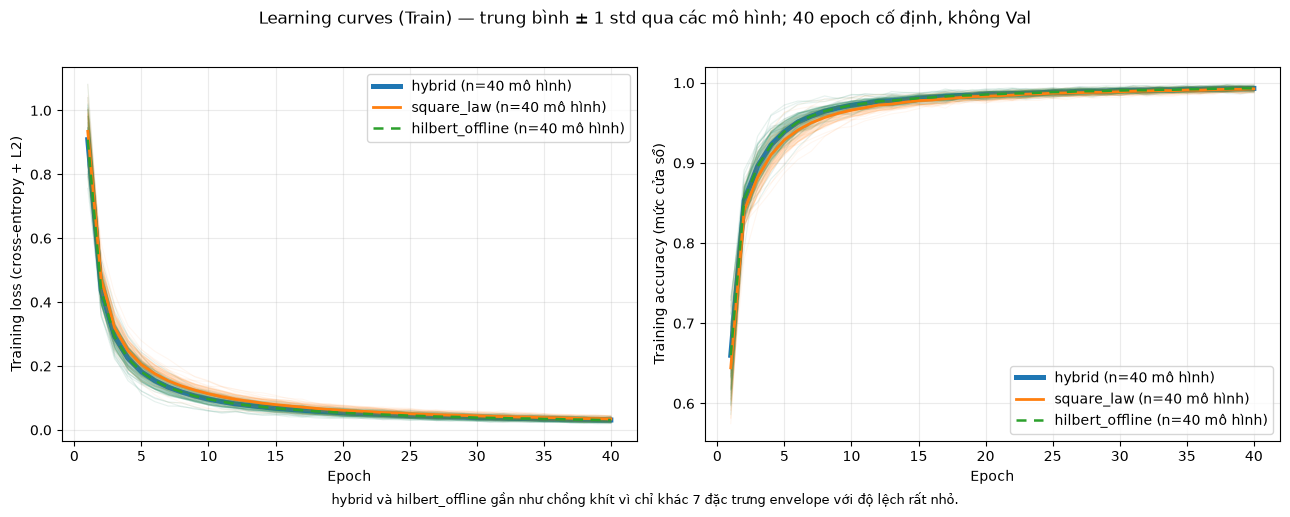

,method,loss_epoch_1,loss_cuoi_mean,loss_cuoi_std,acc_cuoi_mean,acc_cuoi_std,loss_giam_10_epoch_cuoi_%
0,hybrid,0.9086,0.0311,0.0060,0.9930,0.0025,19.2748
1,square_law,0.9345,0.0344,0.0066,0.9923,0.0027,21.8694
2,hilbert_offline,0.9083,0.0311,0.0060,0.9929,0.0025,19.2266


Đã lưu learning_curves.png và learning_curves_summary.csv. Nếu loss vẫn giảm rõ ở các epoch cuối, mô hình chưa hội tụ hẳn trên Train.


In [6]:
# CELL 5b — Learning curves: Training Loss / Training Accuracy
METHOD_COLORS = {'hybrid': '#1f77b4', 'square_law': '#ff7f0e', 'hilbert_offline': '#2ca02c'}
# Hybrid và Hilbert gần như chồng khít: vẽ Hybrid dày ở dưới, Hilbert nét đứt ở trên để thấy cả hai
LINE_STYLE = {'hybrid': dict(linestyle='-', linewidth=3.6, zorder=2),
              'square_law': dict(linestyle='-', linewidth=2.0, zorder=3),
              'hilbert_offline': dict(linestyle=(0, (4, 3)), linewidth=1.8, zorder=4)}
learning_curves = pd.DataFrame(CURVE_ROWS)
main_curves = learning_curves[learning_curves['variant'] == 'All 28 features'].copy()
n_models = {m: int(main_curves[main_curves['method'] == m][['seed', 'fold']].drop_duplicates().shape[0])
            for m in METHODS}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, metric, ylabel in ((axes[0], 'loss', 'Training loss (cross-entropy + L2)'),
                           (axes[1], 'accuracy', 'Training accuracy (mức cửa sổ)')):
    for method in METHODS:
        g = main_curves[main_curves['method'] == method]
        for _, curve in g.groupby(['seed', 'fold']):
            ax.plot(curve['epoch'], curve[metric], color=METHOD_COLORS[method], alpha=0.06, linewidth=0.8)
        agg = g.groupby('epoch')[metric].agg(['mean', 'std'])
        ax.plot(agg.index, agg['mean'], color=METHOD_COLORS[method],
                label=f'{method} (n={n_models[method]} mô hình)', **LINE_STYLE[method])
        ax.fill_between(agg.index, agg['mean'] - agg['std'], agg['mean'] + agg['std'],
                        color=METHOD_COLORS[method], alpha=0.18)
    ax.set_xlabel('Epoch')
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.25)
    ax.legend()
fig.suptitle(f'Learning curves (Train) — trung bình ± 1 std qua các mô hình; {EPOCHS} epoch cố định, không Val', y=1.02)
fig.text(0.5, -0.01, 'hybrid và hilbert_offline gần như chồng khít vì chỉ khác 7 đặc trưng envelope với độ lệch rất nhỏ.',
         ha='center', fontsize=9)
plt.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, 'learning_curves.png'), dpi=150, bbox_inches='tight')
plt.show()

# Chẩn đoán hội tụ trên Train (mô tả, không dùng để chỉnh theo Test)
diag_rows, summary_rows = [], []
for method in METHODS:
    g = main_curves[main_curves['method'] == method]
    last_epoch = int(g['epoch'].max())
    first, last = g[g['epoch'] == 1], g[g['epoch'] == last_epoch]
    mean_loss = g.groupby('epoch')['loss'].mean()
    k_back = min(10, last_epoch - 1)
    drop_last = 100 * (mean_loss.loc[last_epoch - k_back] - mean_loss.loc[last_epoch]) / mean_loss.loc[last_epoch - k_back]
    diag_rows.append({'method': method, 'loss_epoch_1': first['loss'].mean(),
                      'loss_cuoi_mean': last['loss'].mean(), 'loss_cuoi_std': last['loss'].std(),
                      'acc_cuoi_mean': last['accuracy'].mean(), 'acc_cuoi_std': last['accuracy'].std(),
                      f'loss_giam_{k_back}_epoch_cuoi_%': drop_last})
    stats = g.groupby('epoch').agg(loss_mean=('loss', 'mean'), loss_std=('loss', 'std'),
                                   acc_mean=('accuracy', 'mean'), acc_std=('accuracy', 'std')).reset_index()
    summary_rows.append(stats.assign(method=method))
learning_curve_diag = pd.DataFrame(diag_rows)
display(learning_curve_diag.round(4))
pd.concat(summary_rows, ignore_index=True).to_csv(os.path.join(OUTPUT_DIR, 'learning_curves_summary.csv'), index=False)
print('Đã lưu learning_curves.png và learning_curves_summary.csv. Nếu loss vẫn giảm rõ ở các epoch cuối, '
      'mô hình chưa hội tụ hẳn trên Train.')

## 4. Báo cáo mức file

- **Theo seed**: Accuracy và Macro-F1 gộp theo file qua `k` fold (mỗi file đúng một lần), rồi **mean ± std qua N seed** (std mẫu, `ddof=1`; chỉ để mô tả độ nhạy với cách chia và khởi tạo, **không** dùng để suy diễn).
- **Bất định**: CI 95% **bootstrap theo file** (resample 40 file có hoàn lại, cùng một chỉ số file cho mọi phương pháp, rồi lấy trung bình qua seed). Không dùng p-value.
- **So sánh cặp**: hiệu số `Hybrid − phương pháp khác` trên cùng các lần resample, kèm CI. Lớp vắng mặt hoàn toàn trong mẫu bootstrap bị bỏ khỏi trung bình Macro-F1.
- Với **40 file, 1 file = 2,5 điểm %** accuracy; Normal chỉ có 4 file, nên recall Normal có độ phân giải rất thô.

In [7]:
# CELL 6 — Hàm thống kê (mức file) + bootstrap theo file
K_CLS = len(CLASS_NAMES)
CLASS_IDX = {c: i for i, c in enumerate(CLASS_NAMES)}
N_FILES = len(ALL_FILES)
BOOT_RNG = np.random.default_rng(BOOT_SEED)
BOOT_IDX = BOOT_RNG.integers(0, N_FILES, size=(N_BOOT, N_FILES))   # dùng chung cho MỌI phương pháp/điều kiện


def replicate_arrays(pred_df, rep_cols=('seed',)):
    """(R, n_files) nhãn thực/dự đoán; mỗi bản sao (replicate) là một seed (hoặc seed × draw)."""
    T, P, keys = [], [], []
    for key, g in pred_df.groupby(list(rep_cols), sort=True):
        g = g.set_index('file_id').reindex(ALL_FILES)
        if g['y_true'].isna().any():
            raise ValueError(f'Bản sao {key}: thiếu dự đoán cho một số file.')
        T.append(g['y_true'].map(CLASS_IDX).to_numpy())
        P.append(g['y_pred'].map(CLASS_IDX).to_numpy())
        keys.append(key if isinstance(key, tuple) else (key,))
    return np.asarray(T), np.asarray(P), keys


def confusion_counts(T, P):
    """T, P: (..., n) -> (..., K, K) đếm (hàng = thực, cột = dự đoán)."""
    lead = T.shape[:-1]
    n = T.shape[-1]
    n_lead = int(np.prod(lead)) if lead else 1
    codes = (T * K_CLS + P).reshape(n_lead, n) + (np.arange(n_lead) * K_CLS * K_CLS)[:, None]
    return np.bincount(codes.ravel(), minlength=n_lead * K_CLS * K_CLS).reshape(*lead, K_CLS, K_CLS)


def accuracy_from_cm(cm):
    return np.trace(cm, axis1=-2, axis2=-1) / cm.sum(axis=(-2, -1))


def macro_f1_from_cm(cm):
    tp = np.diagonal(cm, axis1=-2, axis2=-1).astype(float)
    fp = cm.sum(axis=-2) - tp
    fn = cm.sum(axis=-1) - tp
    denom = 2 * tp + fp + fn
    present = (cm.sum(axis=-1) + cm.sum(axis=-2)) > 0
    f1 = np.where(denom > 0, 2 * tp / np.where(denom > 0, denom, 1.0), 0.0)
    return (f1 * present).sum(axis=-1) / present.sum(axis=-1)


def bootstrap_stats(T, P, idx_matrix=BOOT_IDX):
    """Accuracy và Macro-F1 (trung bình qua các bản sao) cho mỗi lần resample file."""
    cm = confusion_counts(T[:, idx_matrix], P[:, idx_matrix])       # (R, B, K, K)
    return accuracy_from_cm(cm).mean(axis=0), macro_f1_from_cm(cm).mean(axis=0)


def percentile_ci(values, alpha=CI_ALPHA):
    lo, hi = np.percentile(values, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    return float(lo), float(hi)


def summarize_conditions(pred_df, cond_col, order, reference, rep_cols=('seed',), margin=None):
    """Tóm tắt theo điều kiện (phương pháp/variant): mean ± std qua seed, CI bootstrap theo file,
    hiệu số cặp so với `reference` trên cùng các lần resample."""
    arrays, boots, per_seed_rows, cms, summary = {}, {}, [], {}, []
    for cond in order:
        T, P, keys = replicate_arrays(pred_df[pred_df[cond_col] == cond], rep_cols)
        arrays[cond] = (T, P)
        cm_rep = confusion_counts(T, P)                              # (R, K, K)
        acc_rep, f1_rep = accuracy_from_cm(cm_rep), macro_f1_from_cm(cm_rep)
        seeds_of = np.array([k[0] for k in keys])
        seed_list = np.unique(seeds_of)
        acc_seed = np.array([acc_rep[seeds_of == s].mean() for s in seed_list])
        f1_seed = np.array([f1_rep[seeds_of == s].mean() for s in seed_list])
        for s, a, f in zip(seed_list, acc_seed, f1_seed):
            per_seed_rows.append({cond_col: cond, 'seed': int(s), 'accuracy': a, 'macro_f1': f})
        boots[cond] = bootstrap_stats(T, P)
        cms[cond] = cm_rep.sum(axis=0)                                # tổng các CM theo seed
        a_lo, a_hi = percentile_ci(boots[cond][0])
        f_lo, f_hi = percentile_ci(boots[cond][1])
        summary.append({
            cond_col: cond,
            'accuracy_mean': acc_seed.mean(), 'accuracy_std_seeds': acc_seed.std(ddof=1) if len(acc_seed) > 1 else np.nan,
            'accuracy_ci_lo': a_lo, 'accuracy_ci_hi': a_hi,
            'macro_f1_mean': f1_seed.mean(), 'macro_f1_std_seeds': f1_seed.std(ddof=1) if len(f1_seed) > 1 else np.nan,
            'macro_f1_ci_lo': f_lo, 'macro_f1_ci_hi': f_hi,
            'n_files': N_FILES, 'n_seeds': int(len(seed_list)),
        })
    summary_df = pd.DataFrame(summary)
    per_seed_df = pd.DataFrame(per_seed_rows)

    delta_rows = []
    ref_row = summary_df[summary_df[cond_col] == reference].iloc[0]
    for cond in order:
        if cond == reference:
            continue
        row = summary_df[summary_df[cond_col] == cond].iloc[0]
        entry = {'reference': reference, 'versus': cond}
        for k, name in enumerate(('accuracy', 'macro_f1')):
            d = boots[reference][k] - boots[cond][k]
            lo, hi = percentile_ci(d)
            entry[f'delta_{name}'] = ref_row[f'{name}_mean'] - row[f'{name}_mean']
            entry[f'delta_{name}_ci_lo'], entry[f'delta_{name}_ci_hi'] = lo, hi
        if margin is not None:
            entry['non_inferior_accuracy'] = bool(entry['delta_accuracy_ci_lo'] > -margin)
            entry['non_inferior_macro_f1'] = bool(entry['delta_macro_f1_ci_lo'] > -margin)
        delta_rows.append(entry)
    return {'summary': summary_df, 'delta': pd.DataFrame(delta_rows),
            'per_seed': per_seed_df, 'cm': cms}


def per_class_recall(pred_df, cond_col, order):
    rows = []
    for cond in order:
        g = pred_df[pred_df[cond_col] == cond]
        for c in CLASS_NAMES:
            sub = g[g['y_true'] == c]
            rows.append({cond_col: cond, 'class': c, 'n_correct': int((sub['y_pred'] == c).sum()),
                         'n_total': int(len(sub)), 'n_files': int(sub['file_id'].nunique()),
                         'recall': float((sub['y_pred'] == c).mean())})
    return pd.DataFrame(rows)


def file_error_table(pred_df, cond_col):
    d = pred_df.assign(wrong=pred_df['y_true'] != pred_df['y_pred'])
    wrong = d[d['wrong']]
    most = (wrong.groupby([cond_col, 'file_id'])['y_pred']
            .agg(lambda s: s.value_counts().index[0]).rename('dự_đoán_hay_gặp'))
    t = (d.groupby([cond_col, 'file_id', 'y_true'])
         .agg(n_sai=('wrong', 'sum'), n_seed=('wrong', 'size')).reset_index())
    t = t[t['n_sai'] > 0].merge(most.reset_index(), on=[cond_col, 'file_id'], how='left')
    return t.sort_values([cond_col, 'n_sai'], ascending=[True, False]).reset_index(drop=True)


main = summarize_conditions(predictions_df, 'method', METHODS, PRIMARY_METHOD, margin=NONINFERIORITY_MARGIN)
summary, delta_table, metrics_by_seed = main['summary'], main['delta'], main['per_seed']
recall_table = per_class_recall(predictions_df, 'method', METHODS)
error_table = file_error_table(predictions_df, 'method')
print('Đã tính xong thống kê mức file.')

Đã tính xong thống kê mức file.


Accuracy / Macro-F1 mức file: mean ± std qua seed và CI 95% bootstrap theo file


,method,accuracy_mean,accuracy_std_seeds,accuracy_ci_lo,accuracy_ci_hi,macro_f1_mean,macro_f1_std_seeds,macro_f1_ci_lo,macro_f1_ci_hi,n_files,n_seeds
0,hybrid,0.9175,0.0290,0.8325,0.9825,0.9137,0.0343,0.8099,0.9807,40,10
1,square_law,0.9100,0.0269,0.8250,0.9751,0.9092,0.0320,0.8054,0.9774,40,10
2,hilbert_offline,0.9175,0.0290,0.8325,0.9825,0.9137,0.0343,0.8099,0.9807,40,10



Theo từng seed (mỗi seed = 40 file, mỗi file test đúng một lần):


method,acc_hybrid,acc_square_law,acc_hilbert_offline,f1_hybrid,f1_square_law,f1_hilbert_offline
seed,,,,,,
42,0.925,0.925,0.925,0.9195,0.9386,0.9195
43,0.950,0.925,0.950,0.9395,0.9194,0.9395
44,0.925,0.900,0.925,0.9195,0.9002,0.9195
45,0.925,0.925,0.925,0.9194,0.9194,0.9194
46,0.950,0.950,0.950,0.9580,0.9580,0.9580
47,0.900,0.900,0.900,0.9002,0.9002,0.9002
48,0.875,0.900,0.875,0.8664,0.9002,0.8664
49,0.900,0.900,0.900,0.9002,0.9002,0.9002
50,0.875,0.850,0.875,0.8566,0.8364,0.8566



Hiệu số cặp (hybrid − phương pháp khác), CI 95% bootstrap theo file (không p-value):


...

Biên non-inferiority chưa chốt (NONINFERIORITY_MARGIN=None): chỉ báo cáo hiệu số và CI.

Recall theo lớp (gộp mọi seed; n_total = số file × số seed):


method,hybrid,square_law,hilbert_offline
class,,,
Normal,1.000,1.000,1.000
IR,0.958,0.917,0.958
OR,0.833,0.833,0.833
B,0.933,0.950,0.933


class,Normal,IR,OR,B
n_correct,40,115,100,112
n_total,40,120,120,120
n_files,4,12,12,12



File bị dự đoán sai (n_sai/n_seed):


,method,file_id,y_true,n_sai,n_seed,dự_đoán_hay_gặp
0,hilbert_offline,197@6_0,OR,10,10,B
1,hilbert_offline,200@6_3,OR,10,10,B
2,hilbert_offline,222_0,B,6,10,Normal
3,hilbert_offline,169_0,IR,5,10,B
4,hilbert_offline,118_0,B,2,10,Normal
5,hybrid,197@6_0,OR,10,10,B
6,hybrid,200@6_3,OR,10,10,B
7,hybrid,222_0,B,6,10,Normal
8,hybrid,169_0,IR,5,10,B
9,hybrid,118_0,B,2,10,Normal


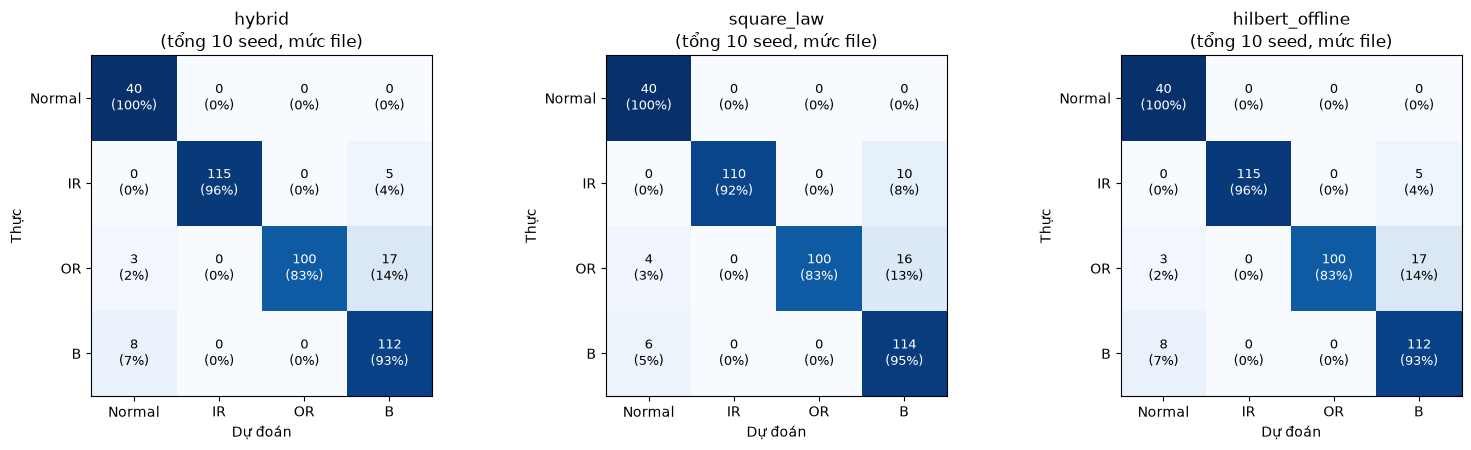

In [22]:
# CELL 7 — Hiển thị kết quả mức file
fmt = {c: '{:.4f}' for c in summary.columns if c.startswith(('accuracy', 'macro_f1'))}
print('Accuracy / Macro-F1 mức file: mean ± std qua seed và CI 95% bootstrap theo file')
display(summary.round(4))

print('\nTheo từng seed (mỗi seed = 40 file, mỗi file test đúng một lần):')
display(metrics_by_seed.pivot(index='seed', columns='method', values='accuracy')[METHODS].round(4)
        .rename(columns=lambda c: f'acc_{c}')
        .join(metrics_by_seed.pivot(index='seed', columns='method', values='macro_f1')[METHODS].round(4)
              .rename(columns=lambda c: f'f1_{c}')))

print(f'\nHiệu số cặp ({PRIMARY_METHOD} − phương pháp khác), CI 95% bootstrap theo file (không p-value):')
display(delta_table.round(4))
if NONINFERIORITY_MARGIN is None:
    print('Biên non-inferiority chưa chốt (NONINFERIORITY_MARGIN=None): chỉ báo cáo hiệu số và CI.')

print('\nRecall theo lớp (gộp mọi seed; n_total = số file × số seed):')
display(recall_table.pivot(index='class', columns='method', values='recall')
        .reindex(CLASS_NAMES)[METHODS].round(3))
display(recall_table[recall_table['method'] == PRIMARY_METHOD][['class', 'n_correct', 'n_total', 'n_files']]
        .set_index('class').T)

print('\nFile bị dự đoán sai (n_sai/n_seed):')
display(error_table)

# --- Confusion matrix: tổng các CM theo seed (mỗi file xuất hiện N_seed lần; KHÔNG phải ensemble) ---
fig, axes = plt.subplots(1, len(METHODS), figsize=(5.2 * len(METHODS), 4.6))
for ax, method in zip(np.atleast_1d(axes), METHODS):
    cm = main['cm'][method]
    norm = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(norm, vmin=0, vmax=1, cmap='Blues')
    for i in range(K_CLS):
        for j in range(K_CLS):
            ax.text(j, i, f'{cm[i, j]}\n({norm[i, j]:.0%})', ha='center', va='center',
                    color='white' if norm[i, j] > 0.5 else 'black', fontsize=9)
    ax.set_xticks(range(K_CLS), CLASS_NAMES)
    ax.set_yticks(range(K_CLS), CLASS_NAMES)
    ax.set_xlabel('Dự đoán')
    ax.set_ylabel('Thực')
    ax.set_title(f'{method}\n(tổng {len(SEEDS)} seed, mức file)')
plt.tight_layout()
plt.show()

### 4.1 Bảng chỉ số chi tiết theo từng seed (mức file)

Mỗi seed = 40 file, mỗi file test đúng một lần. Ngoài Accuracy/Macro-F1: Macro-Precision, Balanced Accuracy (= Macro-Recall), Recall và F1 theo lớp, số file sai và danh sách file sai. Hai dòng cuối là mean và std qua seed (`ddof=1`, chỉ mô tả độ nhạy với cách chia/khởi tạo, không dùng để suy diễn).

In [9]:
# CELL 7b — Bảng chỉ số chi tiết theo từng seed (mức file)
def detailed_metrics_by_seed(pred_df, method):
    T, P, keys = replicate_arrays(pred_df[pred_df['method'] == method], ('seed',))
    cm = confusion_counts(T, P).astype(float)                       # (S, K, K)
    tp = np.diagonal(cm, axis1=-2, axis2=-1)
    support, predicted = cm.sum(axis=-1), cm.sum(axis=-2)
    recall = np.divide(tp, support, out=np.zeros_like(tp), where=support > 0)
    precision = np.divide(tp, predicted, out=np.zeros_like(tp), where=predicted > 0)
    f1 = np.divide(2 * tp, support + predicted, out=np.zeros_like(tp), where=(support + predicted) > 0)
    acc = accuracy_from_cm(cm)
    rows = []
    for r, key in enumerate(keys):
        wrong = [ALL_FILES[j] for j in np.flatnonzero(T[r] != P[r])]
        rows.append({'method': method, 'seed': int(key[0]),
                     'accuracy': acc[r], 'macro_f1': macro_f1_from_cm(cm[r]),
                     'macro_precision': precision[r].mean(), 'balanced_accuracy': recall[r].mean(),
                     **{f'recall_{c}': recall[r, i] for i, c in enumerate(CLASS_NAMES)},
                     **{f'f1_{c}': f1[r, i] for i, c in enumerate(CLASS_NAMES)},
                     'n_files_sai': len(wrong), 'files_sai': ', '.join(wrong) if wrong else '-'})
    return pd.DataFrame(rows)


metrics_detailed = pd.concat([detailed_metrics_by_seed(predictions_df, m) for m in METHODS], ignore_index=True)

# Kiểm tra nhất quán với bảng theo seed ở mục 4
chk = metrics_detailed.merge(metrics_by_seed, on=['method', 'seed'], suffixes=('', '_ref'))
assert len(chk) == len(metrics_detailed)
assert np.allclose(chk['accuracy'], chk['accuracy_ref']) and np.allclose(chk['macro_f1'], chk['macro_f1_ref']), \
    'Bảng chi tiết không khớp bảng theo seed.'

NUM_COLS = (['accuracy', 'macro_f1', 'macro_precision', 'balanced_accuracy']
            + [f'recall_{c}' for c in CLASS_NAMES] + [f'f1_{c}' for c in CLASS_NAMES] + ['n_files_sai'])
for method in METHODS:
    d = metrics_detailed[metrics_detailed['method'] == method].drop(columns='method').set_index('seed')
    stats = d[NUM_COLS].agg(['mean', 'std'])
    shown = pd.concat([d, stats])
    shown['files_sai'] = shown['files_sai'].fillna('')
    print(f'\n=== {method} ===')
    display(shown.round(4))

print('\nTổng hợp mean ± std qua seed:')
agg_rows = []
for method in METHODS:
    g = metrics_detailed[metrics_detailed['method'] == method]
    agg_rows.append({'method': method, **{c: f'{g[c].mean():.4f} ± {g[c].std():.4f}' for c in NUM_COLS}})
display(pd.DataFrame(agg_rows).set_index('method').T)
metrics_detailed.to_csv(os.path.join(OUTPUT_DIR, 'metrics_by_seed_detailed.csv'), index=False)


=== hybrid ===


,accuracy,macro_f1,macro_precision,balanced_accuracy,recall_Normal,recall_IR,recall_OR,recall_B,f1_Normal,f1_IR,f1_OR,f1_B,n_files_sai,files_sai
42,0.9250,0.9195,0.9115,0.9375,1.0,1.0000,0.8333,0.9167,0.8889,1.0000,0.9091,0.8800,3.0000,"197@6_0, 200@6_3, 222_0"
43,0.9500,0.9395,0.9308,0.9583,1.0,1.0000,0.8333,1.0000,0.8889,1.0000,0.9091,0.9600,2.0000,"197@6_0, 200@6_3"
44,0.9250,0.9195,0.9115,0.9375,1.0,1.0000,0.8333,0.9167,0.8889,1.0000,0.9091,0.8800,3.0000,"197@6_0, 200@6_3, 222_0"
45,0.9250,0.9194,0.9143,0.9375,1.0,0.9167,0.8333,1.0000,0.8889,0.9565,0.9091,0.9231,3.0000,"169_0, 197@6_0, 200@6_3"
46,0.9500,0.9580,0.9643,0.9583,1.0,1.0000,0.8333,1.0000,1.0000,1.0000,0.9091,0.9231,2.0000,"197@6_0, 200@6_3"
47,0.9000,0.9002,0.8964,0.9167,1.0,0.9167,0.8333,0.9167,0.8889,0.9565,0.9091,0.8462,4.0000,"169_0, 197@6_0, 200@6_3, 222_0"
48,0.8750,0.8664,0.8590,0.8958,1.0,0.9167,0.8333,0.8333,0.8000,0.9565,0.9091,0.8000,5.0000,"118_0, 169_0, 197@6_0, 200@6_3, 222_0"
49,0.9000,0.9002,0.8964,0.9167,1.0,0.9167,0.8333,0.9167,0.8889,0.9565,0.9091,0.8462,4.0000,"169_0, 197@6_0, 200@6_3, 222_0"
50,0.8750,0.8566,0.8512,0.8958,1.0,0.9167,0.8333,0.8333,0.7273,0.9565,0.9091,0.8333,5.0000,"118_0, 169_0, 197@6_0, 200@6_3, 222_0"
51,0.9500,0.9580,0.9643,0.9583,1.0,1.0000,0.8333,1.0000,1.0000,1.0000,0.9091,0.9231,2.0000,"197@6_0, 200@6_3"



=== square_law ===


,accuracy,macro_f1,macro_precision,balanced_accuracy,recall_Normal,recall_IR,recall_OR,recall_B,f1_Normal,f1_IR,f1_OR,f1_B,n_files_sai,files_sai
42,0.9250,0.9386,0.9500,0.9375,1.0,0.9167,0.8333,1.0000,1.0000,0.9565,0.9091,0.8889,3.000,"169_0, 197@6_0, 200@6_3"
43,0.9250,0.9194,0.9143,0.9375,1.0,0.9167,0.8333,1.0000,0.8889,0.9565,0.9091,0.9231,3.000,"169_0, 197@6_0, 200@6_3"
44,0.9000,0.9002,0.8964,0.9167,1.0,0.9167,0.8333,0.9167,0.8889,0.9565,0.9091,0.8462,4.000,"170_1, 197@6_0, 200@6_3, 222_0"
45,0.9250,0.9194,0.9143,0.9375,1.0,0.9167,0.8333,1.0000,0.8889,0.9565,0.9091,0.9231,3.000,"169_0, 197@6_0, 200@6_3"
46,0.9500,0.9580,0.9643,0.9583,1.0,1.0000,0.8333,1.0000,1.0000,1.0000,0.9091,0.9231,2.000,"197@6_0, 200@6_3"
47,0.9000,0.9002,0.8964,0.9167,1.0,0.9167,0.8333,0.9167,0.8889,0.9565,0.9091,0.8462,4.000,"169_0, 197@6_0, 200@6_3, 222_0"
48,0.9000,0.9002,0.8964,0.9167,1.0,0.9167,0.8333,0.9167,0.8889,0.9565,0.9091,0.8462,4.000,"118_0, 169_0, 197@6_0, 200@6_3"
49,0.9000,0.9002,0.8964,0.9167,1.0,0.9167,0.8333,0.9167,0.8889,0.9565,0.9091,0.8462,4.000,"169_0, 197@6_0, 200@6_3, 222_0"
50,0.8500,0.8364,0.8352,0.8750,1.0,0.8333,0.8333,0.8333,0.7273,0.9091,0.9091,0.8000,6.000,"108_3, 118_0, 169_0, 197@6_0, 200@6_3, 222_0"
51,0.9250,0.9194,0.9143,0.9375,1.0,0.9167,0.8333,1.0000,0.8889,0.9565,0.9091,0.9231,3.000,"169_0, 197@6_0, 200@6_3"



=== hilbert_offline ===


,accuracy,macro_f1,macro_precision,balanced_accuracy,recall_Normal,recall_IR,recall_OR,recall_B,f1_Normal,f1_IR,f1_OR,f1_B,n_files_sai,files_sai
42,0.9250,0.9195,0.9115,0.9375,1.0,1.0000,0.8333,0.9167,0.8889,1.0000,0.9091,0.8800,3.0000,"197@6_0, 200@6_3, 222_0"
43,0.9500,0.9395,0.9308,0.9583,1.0,1.0000,0.8333,1.0000,0.8889,1.0000,0.9091,0.9600,2.0000,"197@6_0, 200@6_3"
44,0.9250,0.9195,0.9115,0.9375,1.0,1.0000,0.8333,0.9167,0.8889,1.0000,0.9091,0.8800,3.0000,"197@6_0, 200@6_3, 222_0"
45,0.9250,0.9194,0.9143,0.9375,1.0,0.9167,0.8333,1.0000,0.8889,0.9565,0.9091,0.9231,3.0000,"169_0, 197@6_0, 200@6_3"
46,0.9500,0.9580,0.9643,0.9583,1.0,1.0000,0.8333,1.0000,1.0000,1.0000,0.9091,0.9231,2.0000,"197@6_0, 200@6_3"
47,0.9000,0.9002,0.8964,0.9167,1.0,0.9167,0.8333,0.9167,0.8889,0.9565,0.9091,0.8462,4.0000,"169_0, 197@6_0, 200@6_3, 222_0"
48,0.8750,0.8664,0.8590,0.8958,1.0,0.9167,0.8333,0.8333,0.8000,0.9565,0.9091,0.8000,5.0000,"118_0, 169_0, 197@6_0, 200@6_3, 222_0"
49,0.9000,0.9002,0.8964,0.9167,1.0,0.9167,0.8333,0.9167,0.8889,0.9565,0.9091,0.8462,4.0000,"169_0, 197@6_0, 200@6_3, 222_0"
50,0.8750,0.8566,0.8512,0.8958,1.0,0.9167,0.8333,0.8333,0.7273,0.9565,0.9091,0.8333,5.0000,"118_0, 169_0, 197@6_0, 200@6_3, 222_0"
51,0.9500,0.9580,0.9643,0.9583,1.0,1.0000,0.8333,1.0000,1.0000,1.0000,0.9091,0.9231,2.0000,"197@6_0, 200@6_3"



Tổng hợp mean ± std qua seed:


method,hybrid,square_law,hilbert_offline
accuracy,0.9175 ± 0.0290,0.9100 ± 0.0269,0.9175 ± 0.0290
macro_f1,0.9137 ± 0.0343,0.9092 ± 0.0320,0.9137 ± 0.0343
macro_precision,0.9100 ± 0.0377,0.9078 ± 0.0348,0.9100 ± 0.0377
balanced_accuracy,0.9313 ± 0.0242,0.9250 ± 0.0224,0.9313 ± 0.0242
recall_Normal,1.0000 ± 0.0000,1.0000 ± 0.0000,1.0000 ± 0.0000
recall_IR,0.9583 ± 0.0439,0.9167 ± 0.0393,0.9583 ± 0.0439
recall_OR,0.8333 ± 0.0000,0.8333 ± 0.0000,0.8333 ± 0.0000
recall_B,0.9333 ± 0.0657,0.9500 ± 0.0583,0.9333 ± 0.0657
f1_Normal,0.8861 ± 0.0807,0.8949 ± 0.0749,0.8861 ± 0.0807
f1_IR,0.9783 ± 0.0229,0.9561 ± 0.0214,0.9783 ± 0.0229


### 4.2 Biểu đồ so sánh Hybrid, Square-Law và FFT Hilbert

Hàng trên: Accuracy và Macro-F1 (cột = trung bình qua seed; thanh lỗi = **CI 95% bootstrap theo file**; chấm đen = từng seed). Hàng dưới: hiệu số cặp `Hybrid − phương pháp khác` với CI bootstrap trên **cùng các lần resample file**; CI chứa 0 nghĩa là chưa phân biệt được hai phương pháp. Hybrid và Hilbert chỉ khác nhau ở 7 đặc trưng envelope với độ lệch rất nhỏ nên hiệu số thường bằng 0.

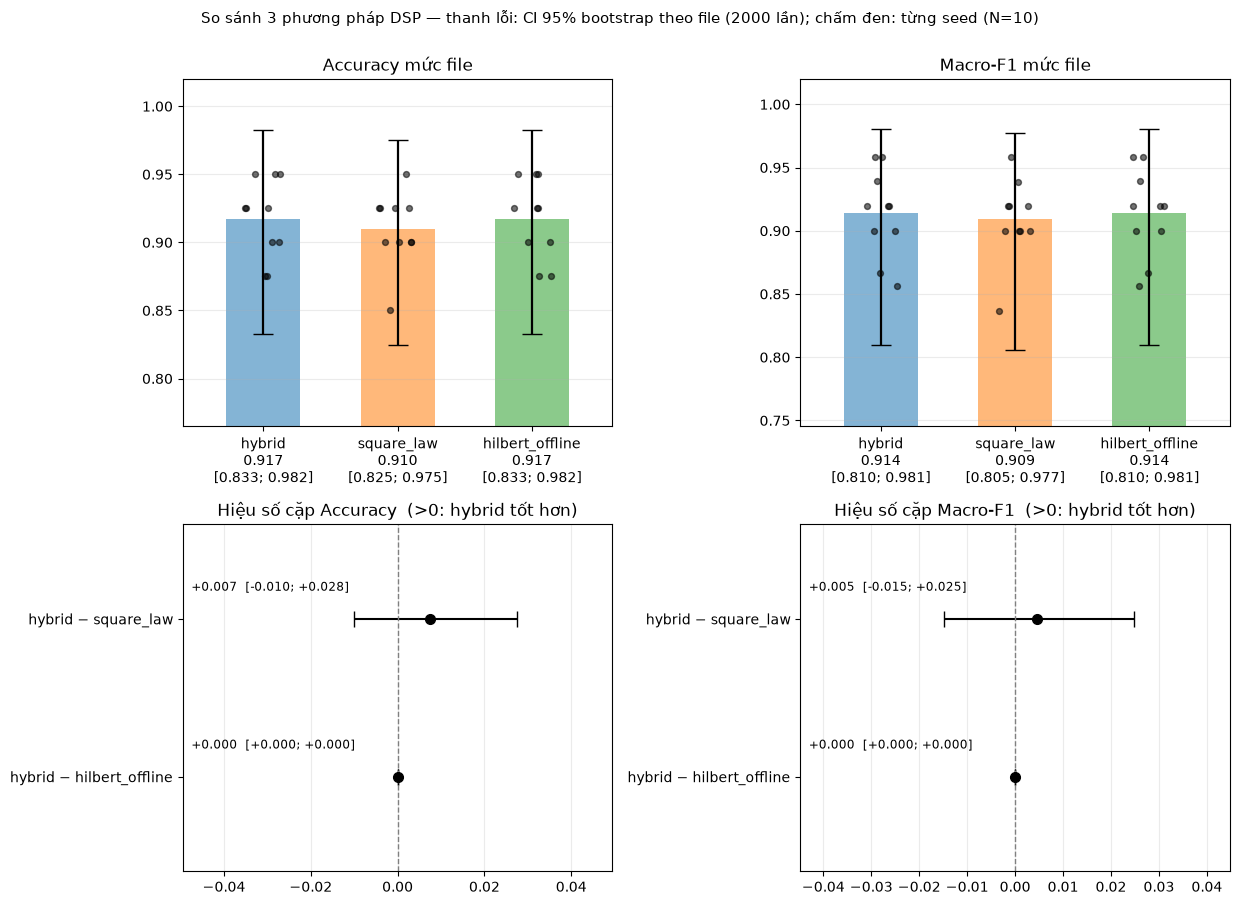

In [21]:
# CELL 7c — So sánh 3 phương pháp (CI 95% bootstrap theo file)
METHOD_COLORS = {'hybrid': '#1f77b4', 'square_law': '#ff7f0e', 'hilbert_offline': '#2ca02c'}
sm = summary.set_index('method').loc[METHODS]
jitter = np.random.default_rng(0)
x = np.arange(len(METHODS))

fig, axes = plt.subplots(2, 2, figsize=(12.5, 9))
for ax, metric, title in ((axes[0, 0], 'accuracy', 'Accuracy mức file'),
                          (axes[0, 1], 'macro_f1', 'Macro-F1 mức file')):
    mean = sm[f'{metric}_mean'].to_numpy()
    lo, hi = sm[f'{metric}_ci_lo'].to_numpy(), sm[f'{metric}_ci_hi'].to_numpy()
    ax.bar(x, mean, color=[METHOD_COLORS[m] for m in METHODS], alpha=0.55, width=0.55)
    ax.errorbar(x, mean, yerr=np.vstack([mean - lo, hi - mean]), fmt='none', ecolor='black', capsize=7, linewidth=1.6)
    for i, method in enumerate(METHODS):
        vals = metrics_by_seed[metrics_by_seed['method'] == method][metric].to_numpy()
        ax.scatter(i + jitter.uniform(-0.14, 0.14, len(vals)), vals, s=18, color='black', alpha=0.55, zorder=3)
    low_bound = min(lo.min(), metrics_by_seed[metric].min())
    ax.set_ylim(max(0.0, low_bound - 0.06), 1.02)
    ax.set_xlim(-0.6, len(METHODS) - 0.4)
    ax.set_xticks(x, [f'{m}\n{mean[i]:.3f}\n[{lo[i]:.3f}; {hi[i]:.3f}]' for i, m in enumerate(METHODS)])
    ax.set_title(title)
    ax.grid(axis='y', alpha=0.25)

others = [m for m in METHODS if m != PRIMARY_METHOD]
dt = delta_table.set_index('versus').loc[others]
ypos = np.arange(len(others))[::-1]
for ax, name, title in ((axes[1, 0], 'accuracy', 'Hiệu số cặp Accuracy'),
                        (axes[1, 1], 'macro_f1', 'Hiệu số cặp Macro-F1')):
    d = dt[f'delta_{name}'].to_numpy()
    lo, hi = dt[f'delta_{name}_ci_lo'].to_numpy(), dt[f'delta_{name}_ci_hi'].to_numpy()
    ax.errorbar(d, ypos, xerr=np.vstack([d - lo, hi - d]), fmt='o', color='black', capsize=6, markersize=7)
    ax.axvline(0, color='gray', linestyle='--', linewidth=1)
    if NONINFERIORITY_MARGIN is not None:
        ax.axvline(-NONINFERIORITY_MARGIN, color='red', linestyle=':', label=f'biên non-inferiority −{NONINFERIORITY_MARGIN}')
        ax.legend(loc='lower right', fontsize=8)
    for yi, di, loi, hii in zip(ypos, d, lo, hi):
        ax.text(0.02, yi + 0.16, f'{di:+.3f}  [{loi:+.3f}; {hii:+.3f}]', transform=ax.get_yaxis_transform(),
                fontsize=8.5, va='bottom')
    bound = max(0.02, float(np.nanmax(np.abs(np.concatenate([lo, hi])))) * 1.8)
    ax.set_xlim(-bound, bound)
    ax.set_ylim(-0.6, len(others) - 0.4)
    ax.set_yticks(ypos, [f'{PRIMARY_METHOD} − {m}' for m in others])
    ax.set_title(title + '  (>0: ' + PRIMARY_METHOD + ' tốt hơn)')
    ax.grid(axis='x', alpha=0.25)
fig.suptitle(f'So sánh 3 phương pháp DSP — thanh lỗi: CI 95% bootstrap theo file ({N_BOOT} lần); chấm đen: từng seed (N={len(SEEDS)})',
             y=1.0, fontsize=11)
plt.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, 'compare_methods_ci.png'), dpi=150, bbox_inches='tight')
plt.show()

## 5. Quét SNR (chống ceiling effect)

Cộng **AWGN vào tín hiệu thô** (DE, sau khi resample về 12 kHz, trước BPF/envelope) rồi **trích lại đặc trưng** cho từng phương pháp. Quy ước:

- SNR tính theo công suất AC của chính file đó; nhiễu có seed cố định theo `(SNR, lần rút, file)` nên **cả ba phương pháp nhận đúng cùng một tín hiệu nhiễu** (so sánh cặp).
- Train **không** bị nhiễu và **không fit lại**: mỗi Test nhiễu dùng đúng mô hình và scaler của cùng `(phương pháp, seed, fold)` từ mục 3. Vì vậy đây là kiểm tra **lệch phân phối** (huấn luyện sạch, kiểm tra nhiễu), không phải huấn luyện chịu nhiễu.
- Các mức SNR là `[TBD]` phải chốt trước khi chạy. Nếu ở một mức, accuracy xấp xỉ tỉ lệ lớp đa số (đường chấm trên biểu đồ), mô hình đang đoán gần như một lớp và mức đó không còn mang thông tin.
- Trước khi quét, notebook **tái tạo đặc trưng sạch** của vài file (mọi file Normal + 1 file mỗi lớp lỗi) bằng pipeline hiện tại và so với bảng đặc trưng. Nếu lệch, bảng đã lỗi thời so với `dsp`/`io_utils` hiện tại và notebook dừng.

In [11]:
# CELL 8 — Hàm cho nhánh nhiễu
def find_raw_manifest():
    candidates = [os.path.join(FEATURES_DIR, 'manifest_filtered.csv'),
                  os.path.join(FEATURES_DIR, 'manifest.csv')]
    path = next((p for p in candidates if os.path.isfile(p)), None)
    if path is None:
        return None, 'không thấy manifest_filtered.csv/manifest.csv'
    raw = pd.read_csv(path)
    required = ['file_path', 'label', 'fault_diameter_mils', 'resolved_sample_rate_hz',
                'resolved_sample_rate_source', 'rpm', 'rpm_source']
    missing = [c for c in required if c not in raw.columns]
    if missing:
        return None, f'manifest thiếu cột {missing}'

    stage1_dir = os.path.abspath('../giai_doan_1_tien_xu_ly')
    project_root = os.path.abspath('../../')

    def resolve_raw_path(value):
        p = os.path.expandvars(os.path.expanduser(str(value)))
        candidates_ = [p] if os.path.isabs(p) else [
            os.path.abspath(os.path.join(stage1_dir, p)),
            os.path.abspath(os.path.join(project_root, p)),
            os.path.abspath(p),
        ]
        return next((c for c in candidates_ if os.path.isfile(c)), candidates_[0])

    raw['file_id'] = raw['file_path'].map(file_stem)
    raw = raw[raw['file_id'].isin(set(ALL_FILES)) & raw['label'].astype(str).isin(CLASS_NAMES)].copy()
    raw['file_path'] = raw['file_path'].map(resolve_raw_path)
    n_missing_path = int((~raw['file_path'].map(os.path.isfile)).sum())
    missing_ids = sorted(set(ALL_FILES) - set(raw['file_id']))
    if n_missing_path or missing_ids or raw['file_id'].duplicated().any():
        return None, (f'không ghép đủ dữ liệu raw: {n_missing_path} đường dẫn thiếu, '
                      f'{len(missing_ids)} file chưa có trong manifest')
    return raw.reset_index(drop=True), path


def check_dsp_methods():
    probe = np.random.default_rng(0).standard_normal(4096)
    for method in METHODS:
        try:
            dsp.envelope_by_method(probe, TARGET_FS_HZ, band=BAND_HZ, method=method,
                                   lp_cutoff=LP_CUTOFF_HZ, bandpass_order=BANDPASS_ORDER,
                                   lowpass_order=LOWPASS_ORDER)
        except Exception as exc:
            raise RuntimeError(f'dsp.envelope_by_method không hỗ trợ method={method!r}: '
                               'cập nhật common/dsp.py.') from exc


def build_feature_table_for(raw_manifest, method, loader):
    df = features_full.build_full_feature_table(
        raw_manifest, band_hz=BAND_HZ, load_de_signal_fn=loader,
        window_size=WINDOW_SIZE, stride=STRIDE, warmup_samples=WARMUP_SAMPLES,
        target_fs_hz=TARGET_FS_HZ, lp_cutoff_hz=LP_CUTOFF_HZ,
        bandpass_order=BANDPASS_ORDER, lowpass_order=LOWPASS_ORDER,
        envelope_method=method,
    )
    df[GROUP_COL] = df[GROUP_COL].astype(str)
    df[LABEL_COL] = df[LABEL_COL].astype(str)
    return df.sort_values([GROUP_COL, 'window_idx']).reset_index(drop=True)


def run_parity_check(raw_manifest):
    """Tái tạo đặc trưng sạch (không nhiễu) của vài file và so với bảng đặc trưng."""
    have = set(raw_manifest['file_id'])
    chosen = [f for f in ALL_FILES if LABEL_BY_FILE[f] == 'Normal']
    chosen += [sorted(f for f in ALL_FILES if LABEL_BY_FILE[f] == c)[0] for c in CLASS_NAMES if c != 'Normal']
    chosen = [f for f in chosen if f in have]
    subset = raw_manifest[raw_manifest['file_id'].isin(chosen)].reset_index(drop=True)
    problems = []
    for method in METHODS:
        rebuilt = build_feature_table_for(subset, method, io_utils.load_de_signal_resampled)
        table = feature_tables[method]
        table = table[table[GROUP_COL].isin(chosen)].reset_index(drop=True)
        same_keys = (len(rebuilt) == len(table)
                     and (rebuilt[[GROUP_COL, 'window_idx']].to_numpy() == table[[GROUP_COL, 'window_idx']].to_numpy()).all())
        if not same_keys:
            problems.append(f'{method}: số cửa sổ/khóa khác bảng ({len(rebuilt)} vs {len(table)})')
            continue
        bad = ~np.isclose(rebuilt[FEATURE_COLS].to_numpy(float), table[FEATURE_COLS].to_numpy(float),
                          rtol=1e-7, atol=1e-9)
        if bad.any():
            bad_files = sorted(rebuilt.loc[bad.any(axis=1), GROUP_COL].unique())
            problems.append(f'{method}: đặc trưng khác bảng ở {bad_files}')
    if problems:
        raise RuntimeError('Parity check THẤT BẠI — bảng đặc trưng không khớp pipeline hiện tại:\n  - '
                           + '\n  - '.join(problems)
                           + '\nChạy lại notebook tạo bảng đặc trưng (và tạo lại manifest) rồi chạy lại.')
    print(f'Parity check: ĐẠT trên {len(chosen)} file × {len(METHODS)} phương pháp.')


def add_awgn(signal, snr_db, seed):
    signal = np.asarray(signal, dtype=np.float64)
    centered = signal - np.mean(signal)                  # công suất AC: DC không chi phối SNR
    signal_power = np.mean(centered ** 2)
    noise = np.random.default_rng(seed).standard_normal(signal.shape)
    noise_power = np.mean(noise ** 2)
    if signal_power <= 0 or noise_power <= 0:
        return signal.copy()
    noise *= np.sqrt(signal_power / (10.0 ** (snr_db / 10.0)) / noise_power)
    return signal + noise


def awgn_seed(snr_db, draw, file_id):
    text = f'CWRU-AWGN-v2|{snr_db}|{draw}|{file_id}'
    return int(hashlib.sha256(text.encode('utf-8')).hexdigest()[:8], 16)


def make_awgn_loader(snr_db, draw):
    def loader(filepath, source_fs_hz, target_fs_hz):
        x = io_utils.load_de_signal_resampled(filepath, source_fs_hz, target_fs_hz)
        return add_awgn(x, snr_db, awgn_seed(snr_db, draw, file_stem(filepath)))
    return loader

Manifest raw: f:\CODE\NCKH_TinyML\TinyML_CWRU\notebooks\giai_doan_1_tien_xu_ly\outputs\tables\manifest_filtered.csv (40 file)
Parity check: ĐẠT trên 7 file × 3 phương pháp.
Trích đặc trưng nhiễu: hybrid           SNR= 20 dB, lần rút 0
Trích đặc trưng nhiễu: square_law       SNR= 20 dB, lần rút 0
Trích đặc trưng nhiễu: hilbert_offline  SNR= 20 dB, lần rút 0
Trích đặc trưng nhiễu: hybrid           SNR= 12 dB, lần rút 0
Trích đặc trưng nhiễu: square_law       SNR= 12 dB, lần rút 0
Trích đặc trưng nhiễu: hilbert_offline  SNR= 12 dB, lần rút 0
Trích đặc trưng nhiễu: hybrid           SNR=  8 dB, lần rút 0
Trích đặc trưng nhiễu: square_law       SNR=  8 dB, lần rút 0
Trích đặc trưng nhiễu: hilbert_offline  SNR=  8 dB, lần rút 0
Trích đặc trưng nhiễu: hybrid           SNR=  4 dB, lần rút 0
Trích đặc trưng nhiễu: square_law       SNR=  4 dB, lần rút 0
Trích đặc trưng nhiễu: hilbert_offline  SNR=  4 dB, lần rút 0
Trích đặc trưng nhiễu: hybrid           SNR=  0 dB, lần rút 0
Trích đặc trưng nhiễu

,snr_db,method,accuracy_mean,accuracy_std_seeds,accuracy_ci_lo,accuracy_ci_hi,macro_f1_mean,macro_f1_ci_lo,macro_f1_ci_hi
0,20,hybrid,0.9150,0.0337,0.8300,0.9825,0.9112,0.8043,0.9805
1,20,square_law,0.9125,0.0243,0.8225,0.9825,0.9168,0.8156,0.9805
2,20,hilbert_offline,0.9125,0.0317,0.8275,0.9800,0.9082,0.7998,0.9791
3,12,hybrid,0.9050,0.0405,0.8225,0.9701,0.9125,0.8233,0.9731
4,12,square_law,0.8475,0.0381,0.7424,0.9300,0.8695,0.7657,0.9377
5,12,hilbert_offline,0.8975,0.0432,0.8125,0.9675,0.9060,0.8150,0.9685
6,8,hybrid,0.7250,0.0707,0.6225,0.8201,0.7504,0.6438,0.8227
7,8,square_law,0.7350,0.0637,0.6200,0.8350,0.7551,0.6330,0.8328
8,8,hilbert_offline,0.7275,0.0546,0.6200,0.8250,0.7519,0.6439,0.8258
9,4,hybrid,0.4325,0.0290,0.3125,0.5451,0.4378,0.3284,0.5010


Hiệu số cặp (hybrid − phương pháp khác) theo SNR:


,snr_db,versus,delta_accuracy,delta_accuracy_ci_lo,delta_accuracy_ci_hi,delta_macro_f1,delta_macro_f1_ci_lo,delta_macro_f1_ci_hi
0,20,square_law,0.0025,-0.0400,0.0425,-0.0056,-0.0630,0.0378
1,20,hilbert_offline,0.0025,0.0000,0.0075,0.0030,0.0000,0.0094
2,12,square_law,0.0575,0.0050,0.1225,0.0430,-0.0082,0.1041
3,12,hilbert_offline,0.0075,0.0000,0.0200,0.0065,0.0000,0.0173
4,8,square_law,-0.0100,-0.0850,0.0675,-0.0047,-0.0831,0.0764
5,8,hilbert_offline,-0.0025,-0.0125,0.0075,-0.0015,-0.0123,0.0090
6,4,square_law,-0.0550,-0.1101,0.0000,-0.0407,-0.0934,0.0082
7,4,hilbert_offline,-0.0075,-0.0200,0.0050,-0.0050,-0.0194,0.0095
8,0,square_law,-0.0425,-0.0825,-0.0075,-0.0358,-0.0816,0.0009
9,0,hilbert_offline,-0.0000,-0.0100,0.0100,-0.0042,-0.0116,0.0024


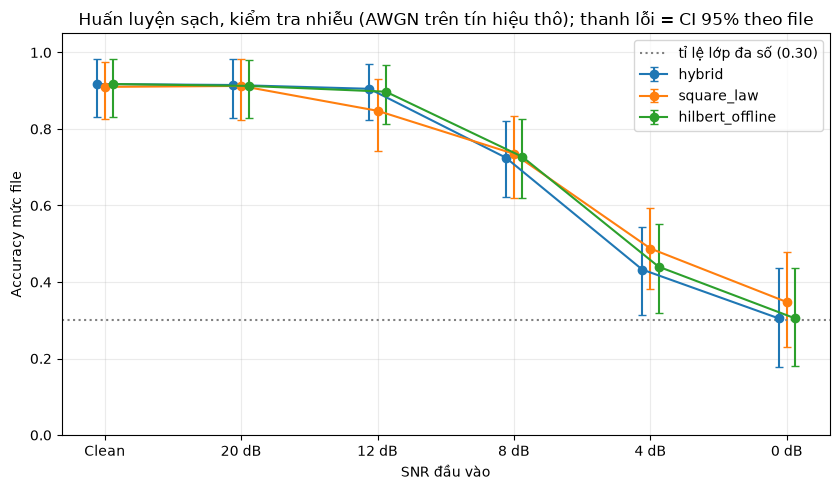

In [12]:
# CELL 9 — Chạy quét SNR (bỏ qua có thông báo nếu thiếu dữ liệu raw)
noise_predictions_df = pd.DataFrame()
noise_summary = noise_delta = pd.DataFrame()

RAW_MANIFEST, raw_note = find_raw_manifest() if RUN_NOISE_SWEEP else (None, 'tắt theo cấu hình')
if RAW_MANIFEST is None:
    print(f'Bỏ qua quét SNR: {raw_note}. Các mục khác vẫn hợp lệ; mục 5 chưa được thực hiện.')
else:
    print(f'Manifest raw: {raw_note} ({len(RAW_MANIFEST)} file)')
    check_dsp_methods()
    if RUN_PARITY_CHECK:
        run_parity_check(RAW_MANIFEST)

    # 1) Trích đặc trưng nhiễu (cùng tín hiệu nhiễu cho mọi phương pháp)
    noise_tables = {}
    for snr_db in SNR_LEVELS_DB:
        for draw in range(N_NOISE_DRAWS):
            for method in METHODS:
                print(f'Trích đặc trưng nhiễu: {method:16s} SNR={snr_db:>3} dB, lần rút {draw}')
                noise_tables[(method, snr_db, draw)] = build_feature_table_for(
                    RAW_MANIFEST, method, make_awgn_loader(snr_db, draw))
                clean = feature_tables[method]
                tbl = noise_tables[(method, snr_db, draw)]
                if not (tbl[[GROUP_COL, 'window_idx']].to_numpy() == clean[[GROUP_COL, 'window_idx']].to_numpy()).all():
                    raise RuntimeError('Bảng nhiễu và bảng sạch không cùng tập cửa sổ.')

    # 2) Chấm điểm bằng đúng mô hình/scaler của fold tương ứng (không fit lại)
    noise_rows = []
    for method in METHODS:
        eval_model = models.build_primary_mlp(input_dim=len(FEATURE_COLS), n_classes=len(CLASS_NAMES), **MLP_KWARGS)
        for seed, splits in FOLDS.items():
            for fold_id, (train_files, test_files) in enumerate(splits, start=1):
                weights, scaler = FOLD_STATE[(method, seed, fold_id)]
                eval_model.set_weights(weights)
                for snr_db in SNR_LEVELS_DB:
                    for draw in range(N_NOISE_DRAWS):
                        tbl = noise_tables[(method, snr_db, draw)]
                        test_df = tbl[tbl[GROUP_COL].isin(set(test_files))].reset_index(drop=True)
                        probs = eval_model.predict(scaler.transform(test_df[FEATURE_COLS].to_numpy(dtype=np.float32)),
                                                   verbose=0)
                        for row in aggregate_file_predictions(test_df, probs):
                            row.update(method=method, seed=seed, fold=fold_id, snr_db=snr_db, draw=draw)
                            noise_rows.append(row)
        tf.keras.backend.clear_session()
    noise_predictions_df = pd.DataFrame(noise_rows)

    # 3) Tóm tắt theo SNR: mean ± std qua seed, CI bootstrap theo file, hiệu số cặp
    summaries, deltas = [], []
    for snr_db in SNR_LEVELS_DB:
        sub = noise_predictions_df[noise_predictions_df['snr_db'] == snr_db]
        res = summarize_conditions(sub, 'method', METHODS, PRIMARY_METHOD, rep_cols=('seed', 'draw'))
        summaries.append(res['summary'].assign(snr_db=snr_db))
        deltas.append(res['delta'].assign(snr_db=snr_db))
    noise_summary = pd.concat(summaries, ignore_index=True)
    noise_delta = pd.concat(deltas, ignore_index=True)

    display(noise_summary[['snr_db', 'method', 'accuracy_mean', 'accuracy_std_seeds', 'accuracy_ci_lo',
                           'accuracy_ci_hi', 'macro_f1_mean', 'macro_f1_ci_lo', 'macro_f1_ci_hi']].round(4))
    
    print(f'Hiệu số cặp ({PRIMARY_METHOD} − phương pháp khác) theo SNR:')
    display(noise_delta[['snr_db', 'versus', 'delta_accuracy', 'delta_accuracy_ci_lo', 'delta_accuracy_ci_hi',
                         'delta_macro_f1', 'delta_macro_f1_ci_lo', 'delta_macro_f1_ci_hi']].round(4))

    # 4) Biểu đồ: điểm Clean lấy từ mục 4; thanh lỗi = CI 95% bootstrap theo file
    labels = ['Clean'] + [f'{s} dB' for s in SNR_LEVELS_DB]
    x = np.arange(len(labels))
    majority = file_meta[LABEL_COL].value_counts(normalize=True).max()
    plt.figure(figsize=(8.5, 5))
    for method in METHODS:
        rows = [summary[summary['method'] == method].iloc[0]] + [
            noise_summary[(noise_summary['method'] == method) & (noise_summary['snr_db'] == s)].iloc[0]
            for s in SNR_LEVELS_DB]
        mean = np.array([r['accuracy_mean'] for r in rows])
        lo = np.array([r['accuracy_ci_lo'] for r in rows])
        hi = np.array([r['accuracy_ci_hi'] for r in rows])
        plt.errorbar(x + 0.06 * (METHODS.index(method) - 1), mean,
                     yerr=np.vstack([np.clip(mean - lo, 0, None), np.clip(hi - mean, 0, None)]),
                     marker='o', capsize=3, label=method)
    plt.axhline(majority, color='gray', linestyle=':', label=f'tỉ lệ lớp đa số ({majority:.2f})')
    plt.xticks(x, labels)
    plt.ylim(0, 1.05)
    plt.ylabel('Accuracy mức file')
    plt.xlabel('SNR đầu vào')
    plt.title('Huấn luyện sạch, kiểm tra nhiễu (AWGN trên tín hiệu thô); thanh lỗi = CI 95% theo file')
    plt.grid(alpha=0.25)
    plt.legend()
    plt.tight_layout()
    plt.show()

## 6. Ablation theo nhóm đặc trưng (tùy chọn)

Chỉ chạy khi `RUN_ABLATION = True`. Phương pháp là `PRIMARY_METHOD` **khai báo trước**, không chọn theo kết quả CV (chọn theo Test rồi phân tích tiếp trên các fold đó sẽ phá vỡ nguyên tắc "không chọn dựa trên Test"). Lần lượt bỏ cả nhóm Time, Order hoặc Envelope; `Δ = All − Without` là độ sụt giảm và có CI bootstrap theo file. Chỉ dùng `ABLATION_SEEDS` để giữ chi phí; kết quả mang tính mô tả.

In [13]:
# CELL 10 — Ablation (tùy chọn)
ablation = None
if RUN_ABLATION:
    groups = {'Time-domain': TIME_COLS, 'Order/frequency': ORDER_COLS, 'Envelope': ENV_COLS}
    parts = [predictions_df[(predictions_df['method'] == PRIMARY_METHOD) 
                            & predictions_df['seed'].isin(ABLATION_SEEDS)].assign(variant='All 28 features')]
    for gname, remove in groups.items():
        cols = [c for c in FEATURE_COLS if c not in set(remove)]
        print(f'Ablation: bỏ {gname} -> {len(cols)} đặc trưng')
        parts.append(run_cv(PRIMARY_METHOD, feature_tables[PRIMARY_METHOD], cols, ABLATION_SEEDS, 
                            variant=f'Without {gname}')) # type: ignore
    
    ablation_df = pd.concat(parts, ignore_index=True)
    order = ['All 28 features'] + [f'Without {g}' for g in groups]
    ablation = summarize_conditions(ablation_df, 'variant', order, 'All 28 features')
    display(ablation['summary'].round(4))
    
    print('Độ sụt giảm (All − Without), CI 95% bootstrap theo file:')
    display(ablation['delta'].round(4))
else:
    print('Ablation tắt (RUN_ABLATION=False).')

Ablation: bỏ Time-domain -> 17 đặc trưng
  hybrid           seed 42 xong  (   23s)
  hybrid           seed 43 xong  (   47s)
  hybrid           seed 44 xong  (   72s)
Ablation: bỏ Order/frequency -> 18 đặc trưng
  hybrid           seed 42 xong  (   26s)
  hybrid           seed 43 xong  (   48s)
  hybrid           seed 44 xong  (   71s)
Ablation: bỏ Envelope -> 21 đặc trưng
  hybrid           seed 42 xong  (   22s)
  hybrid           seed 43 xong  (   45s)
  hybrid           seed 44 xong  (   68s)


,variant,accuracy_mean,accuracy_std_seeds,accuracy_ci_lo,accuracy_ci_hi,macro_f1_mean,macro_f1_std_seeds,macro_f1_ci_lo,macro_f1_ci_hi,n_files,n_seeds
0,All 28 features,0.9333,0.0144,0.8500,1.0000,0.9262,0.0115,0.8121,1.000,40,3
1,Without Time-domain,0.9667,0.0144,0.9083,1.0000,0.9639,0.0264,0.8919,1.000,40,3
2,Without Order/frequency,0.9333,0.0144,0.8500,1.0000,0.9390,0.0013,0.8459,1.000,40,3
3,Without Envelope,0.8750,0.0250,0.7750,0.9583,0.8712,0.0213,0.7249,0.958,40,3


Độ sụt giảm (All − Without), CI 95% bootstrap theo file:


,reference,versus,delta_accuracy,delta_accuracy_ci_lo,delta_accuracy_ci_hi,delta_macro_f1,delta_macro_f1_ci_lo,delta_macro_f1_ci_hi
0,All 28 features,Without Time-domain,-0.0333,-0.100,0.0167,-0.0377,-0.1468,0.0355
1,All 28 features,Without Order/frequency,0.0000,-0.075,0.0750,-0.0129,-0.0864,0.0542
2,All 28 features,Without Envelope,0.0583,-0.000,0.1417,0.0549,-0.0146,0.1542


### 6.1 Biểu đồ ablation

Hai cột đầu: Accuracy và Macro-F1 của từng biến thể (cột = trung bình, thanh lỗi = CI 95% bootstrap theo file, chấm = từng seed). Cột ba: độ sụt giảm `All − Without` với CI. **>0**: nhóm đặc trưng bị bỏ có ích; **<0**: bỏ nhóm đó lại tốt hơn. Với 40 file và vài seed, CI thường rất rộng và chứa 0; chỉ đọc khác biệt khi CI không chứa 0.

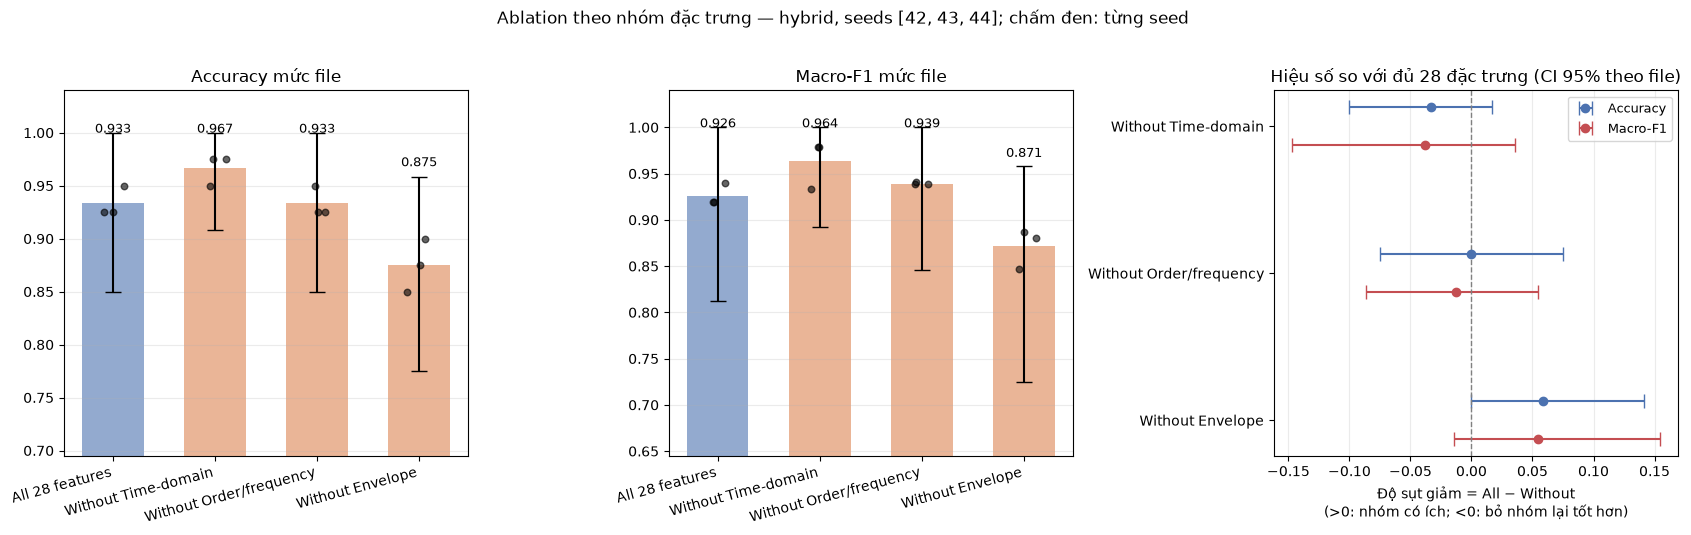

In [20]:
# CELL 10b — Biểu đồ ablation
if ablation is None:
    print('Ablation chưa chạy (RUN_ABLATION=False) nên chưa có biểu đồ.')
else:
    abl_sum = ablation['summary'].set_index('variant')
    abl_delta = ablation['delta'].set_index('versus')
    abl_seed = ablation['per_seed']
    variants = list(abl_sum.index)
    xv = np.arange(len(variants))
    colors = ['#4c72b0'] + ['#dd8452'] * (len(variants) - 1)
    jitter = np.random.default_rng(1)

    fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))
    for ax, metric, title in ((axes[0], 'accuracy', 'Accuracy mức file'), (axes[1], 'macro_f1', 'Macro-F1 mức file')):
        mean = abl_sum[f'{metric}_mean'].to_numpy()
        lo, hi = abl_sum[f'{metric}_ci_lo'].to_numpy(), abl_sum[f'{metric}_ci_hi'].to_numpy()
        ax.bar(xv, mean, color=colors, alpha=0.6, width=0.6)
        ax.errorbar(xv, mean, yerr=np.vstack([np.clip(mean - lo, 0, None), np.clip(hi - mean, 0, None)]),
                    fmt='none', ecolor='black', capsize=6, linewidth=1.5)
        for i, variant in enumerate(variants):
            vals = abl_seed[abl_seed['variant'] == variant][metric].to_numpy()
            ax.scatter(i + jitter.uniform(-0.12, 0.12, len(vals)), vals, s=22, color='black', alpha=0.6, zorder=3)
            ax.text(i, min(hi[i] + 0.01, 1.0), f'{mean[i]:.3f}', ha='center', fontsize=9)
        ax.set_ylim(max(0.0, min(lo.min(), abl_seed[metric].min()) - 0.08), 1.04)
        ax.set_xticks(xv, variants, rotation=15, ha='right')
        ax.set_title(title)
        ax.grid(axis='y', alpha=0.25)

    ax = axes[2]
    ypos = np.arange(len(abl_delta))[::-1]
    for off, name, color, label in ((0.13, 'accuracy', '#4c72b0', 'Accuracy'), (-0.13, 'macro_f1', '#c44e52', 'Macro-F1')):
        d = abl_delta[f'delta_{name}'].to_numpy()
        lo, hi = abl_delta[f'delta_{name}_ci_lo'].to_numpy(), abl_delta[f'delta_{name}_ci_hi'].to_numpy()
        ax.errorbar(d, ypos + off, xerr=np.vstack([d - lo, hi - d]), fmt='o', color=color, capsize=5,
                    markersize=6, label=label)
    ax.axvline(0, color='gray', linestyle='--', linewidth=1)
    ax.set_yticks(ypos, list(abl_delta.index))
    ax.set_xlabel('Độ sụt giảm = All − Without\n(>0: nhóm có ích; <0: bỏ nhóm lại tốt hơn)')
    ax.set_title('Hiệu số so với đủ 28 đặc trưng (CI 95% theo file)')
    ax.legend(loc='best', fontsize=9)
    ax.grid(axis='x', alpha=0.25)
    fig.suptitle(f'Ablation theo nhóm đặc trưng — {PRIMARY_METHOD}, seeds {ABLATION_SEEDS}; chấm đen: từng seed', y=1.02)
    plt.tight_layout()
    fig.savefig(os.path.join(OUTPUT_DIR, 'ablation_chart.png'), dpi=150, bbox_inches='tight')
    plt.show()

## 7. Lưu kết quả và kiểm tra tuân thủ giao thức

In [18]:
# CELL 11 — Lưu kết quả để kiểm toán/tái lập
def save_csv(df, name):
    df.to_csv(os.path.join(OUTPUT_DIR, name), index=False)


save_csv(predictions_df, 'predictions_file_level.csv')
save_csv(metrics_by_seed, 'metrics_by_seed.csv')
save_csv(summary, 'summary.csv')
save_csv(delta_table, 'paired_deltas.csv')
save_csv(recall_table, 'per_class_recall.csv')
save_csv(error_table, 'file_errors.csv')
save_csv(pd.DataFrame([{'method': m, 'true': CLASS_NAMES[i], 'pred': CLASS_NAMES[j], 'count': int(main['cm'][m][i, j])}
                       for m in METHODS for i in range(K_CLS) for j in range(K_CLS)]),
         'confusion_matrix_sum_over_seeds.csv')
if len(noise_predictions_df):
    save_csv(noise_predictions_df, 'noise_predictions_file_level.csv')
    save_csv(noise_summary, 'noise_summary.csv')
    save_csv(noise_delta, 'noise_paired_deltas.csv')
if ablation is not None:
    save_csv(ablation['summary'], 'ablation_summary.csv')
    save_csv(ablation['delta'], 'ablation_deltas.csv')

run_config = {
    'created': time.strftime('%Y-%m-%d %H:%M:%S'),
    'versions': {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,
                 'sklearn': sklearn.__version__, 'tensorflow': tf.__version__},
    'protocol': {'K': K, 'seeds': SEEDS, 'fold_source': FOLD_SOURCE, 'stratify_col': STRAT_COL,
                 'label_col': LABEL_COL, 'group_col': GROUP_COL},
    'model': {'epochs': EPOCHS, 'batch_size': BATCH_SIZE, 'learning_rate': LEARNING_RATE,
              'mlp_kwargs': {k: list(v) if isinstance(v, tuple) else v for k, v in MLP_KWARGS.items()},
              'use_class_weight': USE_CLASS_WEIGHT, 'validation': 'none', 'early_stopping': False},
    'bootstrap': {'n_boot': N_BOOT, 'seed': BOOT_SEED, 'alpha': CI_ALPHA, 'unit': 'file',
                  'noninferiority_margin': NONINFERIORITY_MARGIN},
    'noise': {'run': bool(len(noise_predictions_df)), 'snr_db': SNR_LEVELS_DB, 'draws': N_NOISE_DRAWS,
              'parity_check': bool(RUN_PARITY_CHECK and len(noise_predictions_df))},
    'dsp': {'band_hz': list(BAND_HZ), 'lp_cutoff_hz': LP_CUTOFF_HZ, 'bandpass_order': BANDPASS_ORDER,
            'lowpass_order': LOWPASS_ORDER, 'target_fs_hz': TARGET_FS_HZ},
    'tables': {m: {'path': TABLE_PATHS[m], 'sha256': TABLE_SHA256[m]} for m in METHODS},
    'n_files': int(N_FILES), 'n_windows': int(len(ref)), 'cv_minutes': round(CV_SECONDS / 60, 2),
}
with open(os.path.join(OUTPUT_DIR, 'run_config.json'), 'w', encoding='utf-8') as fh:
    json.dump(run_config, fh, ensure_ascii=False, indent=2)
print(f'Đã lưu kết quả vào {OUTPUT_DIR}')

Đã lưu kết quả vào f:\CODE\NCKH_TinyML\TinyML_CWRU\notebooks\giai_doan_2_model\outputs\training_mlp_v2


In [ ]:
# CELL 12 — Kiểm tra tuân thủ giao thức (tính từ chính lần chạy này)
tested_once = all(sorted(g['file_id']) == ALL_FILES for _, g in predictions_df.groupby(['method', 'seed'])) # type: ignore # type: ignore
same_folds = all(g.groupby('method')['file_id'].apply(lambda s: tuple(sorted(s))).nunique() == 1
                 for _, g in predictions_df.groupby(['seed', 'fold']))
same_seeds = all(set(g['seed']) == set(SEEDS) for _, g in predictions_df.groupby('method')) # type: ignore # type: ignore
min_per_class = int(files_per_class.min())

checklist = pd.DataFrame([
    ('Stratified group k-fold, nhóm = file_id, mỗi file test đúng 1 lần/seed', tested_once,
     f'K={K}; nguồn fold: {FOLD_SOURCE}'),
    ('N seed 42–51, báo cáo đủ', same_seeds and len(SEEDS) == 10, f'{len(SEEDS)} seed'),
    ('Ba phương pháp dùng cùng seed/fold', same_folds and same_seeds, 'so sánh cặp'),
    ('Điều kiện kiểm kê: mỗi lớp ≥ k file', min_per_class >= K, f'lớp ít file nhất: {min_per_class}'),
    ('Z-score chỉ fit trên Train', True, 'StandardScaler trong fit_fold, từng fold'),
    ('Cấu hình DSP chốt từ trước', True, f'band {BAND_HZ} Hz, LP {LP_CUTOFF_HZ} Hz, bậc BPF/LPF {BANDPASS_ORDER}/{LOWPASS_ORDER}'),
    ('MLP/epoch cố định, không early stopping, không Val', True, f'{EPOCHS} epoch; {MLP_KWARGS}'),
    ('Báo cáo mức file: Accuracy, Macro-F1, mean ± std, confusion matrix', True, 'mục 4'),
    ('CI bootstrap theo file', True, f'{N_BOOT} lần resample file'),
    ('Không p-value từ N seed; không std trên cửa sổ', True, 'chỉ std qua seed (mô tả) và CI theo file'),
    ('Quét SNR (AWGN trên tín hiệu thô)', bool(len(noise_predictions_df)),
     f'mức {SNR_LEVELS_DB} dB' if len(noise_predictions_df) else 'CHƯA chạy (thiếu raw/tắt)'),
], columns=['Mục giao thức', 'Đạt', 'Ghi chú'])
checklist['Đạt'] = checklist['Đạt'].map({True: 'ĐẠT', False: 'CHƯA ĐẠT'})
display(checklist)
if (checklist['Đạt'] == 'CHƯA ĐẠT').any():
    print('Lưu ý: có mục giao thức chưa đạt; xem cột Ghi chú trước khi dùng số liệu để kết luận.')

,Mục giao thức,Đạt,Ghi chú
0,"Stratified group k-fold, nhóm = file_id, mỗi f...",ĐẠT,K=4; nguồn fold: manifest_with_folds.csv
1,"N seed 42–51, báo cáo đủ",ĐẠT,10 seed
2,Ba phương pháp dùng cùng seed/fold,ĐẠT,so sánh cặp
3,Điều kiện kiểm kê: mỗi lớp ≥ k file,ĐẠT,lớp ít file nhất: 4
4,Z-score chỉ fit trên Train,ĐẠT,"StandardScaler trong fit_fold, từng fold"
5,Cấu hình DSP chốt từ trước,ĐẠT,"band (2300.0, 3800.0) Hz, LP 750.0 Hz, bậc BPF..."
6,"MLP/epoch cố định, không early stopping, không...",ĐẠT,"40 epoch; {'hidden_units': (32, 16), 'dropout_..."
7,"Báo cáo mức file: Accuracy, Macro-F1, mean ± s...",ĐẠT,mục 4
8,CI bootstrap theo file,ĐẠT,2000 lần resample file
9,Không p-value từ N seed; không std trên cửa sổ,ĐẠT,chỉ std qua seed (mô tả) và CI theo file


## Giới hạn cần nêu khi báo cáo

- **Chỉ CWRU, 40 file.** Mỗi file bằng 2,5 điểm % accuracy; Normal chỉ có 4 file nên không có tập Val riêng khả thi (cấu hình MLP và số epoch được chốt trước). CI bootstrap theo file là cách đo bất định chính; std qua seed chỉ mô tả độ nhạy với cách chia/khởi tạo.
- **Không độc lập giữa các file cùng khuyết tật.** 9 ca lỗi (lớp × đường kính) × 4 tải; mô hình có thể đã thấy cùng một khuyết tật ở tải khác. Kết luận đúng là khả năng nhận ra lỗi *đã thấy ở tải khác*, chưa phải khái quát hóa sang khuyết tật/đường kính mới. Nên bổ sung leave-one-load-out và leave-one-diameter-out như phân tích phụ.
- **Quyết định mức bản ghi.** Accuracy ở đây là quyết định cho cả file (khoảng 115 cửa sổ), không phải độ chính xác của một lần suy luận 170 ms trên MCU.
- **Hybrid và Hilbert** chỉ khác nhau ở 7 đặc trưng envelope với độ lệch rất nhỏ; kết quả phân loại có thể trùng nhau hoàn toàn. Bằng chứng so sánh hai phương pháp này nằm ở độ trung thực DSP và chi phí trên MCU, không nằm ở phân loại.
- Quét SNR là kiểm tra **lệch phân phối** (train sạch, test nhiễu).